# Machine Learning and Data Mining II — Labwork T1: Principal Component Analysis
## Dataset 1 — Stroke Prediction Dataset
`healthcare-dataset-stroke-data.csv`

**Student Name:** [Student Full Name]  
**Student ID:** [Student ID]  
**Academic Year:** [Academic Year]

This notebook covers **Dataset 1** of the two-dataset assignment in TD1-PCA [1].
It contains Part 1 (Study the dataset) and Part 2 (Principal Component Analysis).
This analysis will be combined with **Dataset 2** in the final PDF report.

**Contents:** dataset overview and variable types; data quality and cleaning;
integration and transformation; statistical relationships; PCA computation,
component selection, reconstruction, visualization, and interpretation.


In [1]:
import os
import sys
import tempfile
import textwrap
import io
import base64
from html import escape
from pathlib import Path

# Keep plotting caches outside the dataset and source directories.
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'stroke_pca_mpl'))
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import HTML, display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.labelsize': 10,
    'axes.titlesize': 10, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'legend.fontsize': 8, 'figure.titlesize': 11, 'figure.dpi': 150,
    'savefig.dpi': 150, 'figure.constrained_layout.use': True,
})
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

REPORT_CSS = """<style>
@page { size: A4 portrait; margin: 20mm; }
.stroke-table-wrap { width:100%; max-width:170mm; margin:12px 0; }
.stroke-table { width:100%; table-layout:fixed; border-collapse:collapse;
  font-size:10pt; line-height:1.3; }
.stroke-table caption { caption-side:top; text-align:left; font-weight:600;
  padding:0 0 6px; font-size:10pt; }
.stroke-table th, .stroke-table td { padding:5px 4px; border-bottom:1px solid #d7dee5;
  white-space:normal !important; overflow-wrap:anywhere; vertical-align:top; text-align:left; }
.stroke-table th { background:#edf2f6; }
.stroke-table tbody tr:nth-child(even) { background:#f7f9fb; }
.stroke-caption { max-width:170mm; font-size:10pt; line-height:1.35; margin:4px 0 14px; }
.stroke-figure { width:100%; max-width:170mm; margin:0 0 4mm; break-inside:avoid; }
.stroke-figure img { width:100%; height:auto; }
.jp-RenderedHTMLCommon table { max-width:100%; table-layout:fixed; font-size:10pt; }
.jp-RenderedHTMLCommon td, .jp-RenderedHTMLCommon th { overflow-wrap:anywhere; white-space:normal; }
@media print {
  .jp-Notebook, .jp-Cell, .jp-OutputArea, .jp-OutputArea-output { max-width:170mm !important; }
  .jp-OutputArea-output { overflow:visible !important; }
  .jp-RenderedImage img, .output_png img { max-width:170mm !important; height:auto !important; }
  .stroke-table tr { break-inside:avoid; }
  .stroke-table thead { display:table-header-group; }
  h1, h2, h3, .stroke-table caption { break-after:avoid; }
  p:has(+ table) { break-after:avoid; }
  .stroke-figure, .stroke-figure figcaption { break-inside:avoid; }
}
</style>"""
display(HTML(REPORT_CSS))

def show_table(frame, caption, widths=None, note=None):
    """HTML table with wrapping; compact, non-truncated plain-text fallback."""
    frame = frame.reset_index(drop=True)
    columns = list(frame.columns)
    values = [[str(v) for v in row] for row in frame.itertuples(index=False, name=None)]
    colgroup = '' if widths is None else '<colgroup>' + ''.join(
        f'<col style="width:{w}%">' for w in widths) + '</colgroup>'
    header = '<thead><tr>' + ''.join(f'<th>{escape(str(c))}</th>' for c in columns) + '</tr></thead>'
    body = '<tbody>' + ''.join('<tr>' + ''.join(f'<td>{escape(v)}</td>' for v in row) + '</tr>' for row in values) + '</tbody>'
    html = f'<div class="stroke-table-wrap"><table class="stroke-table"><caption>{escape(caption)}</caption>{colgroup}{header}{body}</table>'
    if note:
        html += f'<p class="stroke-caption">{escape(note)}</p>'
    html += '</div>'
    # Wrap each fallback row into a label/value list rather than a wide ASCII table.
    plain = caption + '\n' + '\n'.join(
        textwrap.fill('; '.join(f'{c}: {v}' for c, v in zip(columns, row)), width=84)
        for row in values)
    if note:
        plain += '\n' + textwrap.fill(note, width=84)
    display({'text/html': html, 'text/plain': plain}, raw=True)

def finish_figure(fig, title, note):
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    titles = [t for t in [fig._suptitle] + [ax.title for ax in fig.axes] if t is not None and t.get_text()]
    overlaps = [(a.get_text(), b.get_text()) for i, a in enumerate(titles) for b in titles[i+1:]
                if a.get_window_extent(renderer).overlaps(b.get_window_extent(renderer))]
    report_values['figure_title_overlap_count'] += len(overlaps)
    assert not overlaps, f'Overlapping figure titles: {overlaps}'
    image_buffer = io.BytesIO()
    fig.savefig(image_buffer, format='png', dpi=300, bbox_inches='tight')
    figure_names = {
        'Figure 1': 'fig1_target.png',
        'Figure 2': 'fig2_boxplots.png',
        'Figure 3': 'fig3_covariance.png',
        'Figure 4a': 'fig4a_corr_main.png',
        'Figure 4b (Appendix)': 'fig4b_corr_full.png',
        'Figure 5': 'fig5_scree.png',
        'Figure 6': 'fig6_reconstruction.png',
        'Figure 7': 'fig7_pca_2d.png',
        'Figure 8': 'fig8_weights.png',
    }
    dataset_dir = Path('.') if Path('healthcare-dataset-stroke-data.csv').is_file() else Path('nhat_stroke')
    figure_dir = dataset_dir / 'figures'
    figure_dir.mkdir(parents=True, exist_ok=True)
    figure_dir.joinpath(figure_names[title.split(':', 1)[0]]).write_bytes(image_buffer.getvalue())
    encoded_png = base64.b64encode(image_buffer.getvalue()).decode('ascii')
    plt.close(fig)
    html = (f'<figure class="stroke-figure"><img alt="{escape(title)}" '
            f'src="data:image/png;base64,{encoded_png}"><figcaption class="stroke-caption">'
            f'<strong>{escape(title)}</strong><br>{escape(note)}</figcaption></figure>')
    display({'text/html':html, 'image/png':encoded_png, 'text/plain':title+'\n'+note}, raw=True)

# Values for the report are derived from this execution, not copied from old outputs.
report_values = {}
report_values['figure_title_overlap_count'] = 0
print('Recorded computational environment:')
for name, version in [('Python', sys.version.split()[0]), ('NumPy', np.__version__),
                      ('Pandas', pd.__version__), ('Matplotlib', matplotlib.__version__),
                      ('Seaborn', sns.__version__), ('Scikit-learn', sklearn.__version__)]:
    print(f' - {name}: {version}')
print(f' - Random state: {RANDOM_STATE}')


Recorded computational environment:
 - Python: 3.14.8
 - NumPy: 2.5.5
 - Pandas: 3.1.1
 - Matplotlib: 3.11.2
 - Seaborn: 0.13.2
 - Scikit-learn: 1.9.1
 - Random state: 42


### Computational Environment

Library versions and `RANDOM_STATE = 42` are recorded for reproducibility.
No train/test split or predictive classifier is used in this exploratory analysis; PCA describes the available dataset.
As in the linear algebra of DM 3 [4], $\mathbf v$ and $-\mathbf v$ define the same principal direction, so a random seed does not eliminate sign ambiguity and all interpretations must match the fitted model's sign convention.


In [2]:
data_path = Path('healthcare-dataset-stroke-data.csv')
if not data_path.is_file():
    data_path = Path('nhat_stroke') / data_path
df_raw = pd.read_csv(data_path)
n_raw, raw_columns = df_raw.shape
input_count = len(df_raw.columns.difference(['id', 'stroke']))
report_values.update(n_raw=n_raw, raw_columns=raw_columns, input_count=input_count)
print(f'Raw dataset: {n_raw:,} rows x {raw_columns} columns')
print(f'Input variables excluding id and stroke: {input_count}')
print('Storage types: ' + ', '.join(f'{dtype}: {count}' for dtype, count in df_raw.dtypes.astype(str).value_counts().items()))
print(f'Non-null BMI: {df_raw.bmi.notna().sum():,} of {n_raw:,}')
print('All attributes and their roles are listed in Table 1.')


Raw dataset: 5,110 rows x 12 columns
Input variables excluding id and stroke: 10
Storage types: str: 5, int64: 4, float64: 3
Non-null BMI: 4,909 of 5,110
All attributes and their roles are listed in Table 1.


## Part 1 — Study the Dataset
### 1.1. Dataset Overview

**Source:** fedesoriano, [Stroke Prediction Dataset — Kaggle](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset) [5].  
**Local file:** `healthcare-dataset-stroke-data.csv`.

The file contains **5,110 records and 12 columns**. Each row is an observation and each column an attribute (DM 2 and DM 3 [2,4]). Excluding the identifier `id` and target `stroke` leaves **10 input variables**, satisfying TD1-PCA's requirement of more than six features [1]. The mixed-type table becomes a numerical matrix only after categorical encoding.

The variables describe demographic characteristics, recorded health conditions, and lifestyle-related information. This study examines their distributions and the main directions of variation captured by PCA.

The file is analyzed as a static cross-sectional benchmark table: no timestamps or follow-up windows are supplied. Population origin and collection protocols are not documented in the supplied file, and the original study design cannot be established from its schema. These limitations restrict temporal, causal, and population-level generalization.


In [3]:
numeric_features = ['age', 'avg_glucose_level', 'bmi']
binary_features = ['hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'stroke']
taxonomy = []
for col in df_raw.columns:
    if col in numeric_features:
        kind, scale, representation, levels = 'Continuous', 'Quantitative', 'Numerical', '—'
    else:
        kind, scale = 'Discrete', 'Qualitative'
        representation = ('Nominal identifier' if col == 'id' else
                          'Binary target' if col == 'stroke' else
                          'Binary nominal' if col in binary_features else 'Multi-class nominal')
        levels = f'{df_raw[col].nunique():,}'
    taxonomy.append([col, kind, scale, representation, levels])
df_taxonomy = pd.DataFrame(taxonomy, columns=[
    'Attribute', 'Discrete / Continuous', 'Quantitative / Qualitative', 'Representation', 'Levels'])
show_table(df_taxonomy, 'Table 1. Variable types in the raw Stroke dataset', [25, 19, 20, 25, 11])


Attribute,Discrete / Continuous,Quantitative / Qualitative,Representation,Levels
id,Discrete,Qualitative,Nominal identifier,"5,110"
gender,Discrete,Qualitative,Multi-class nominal,3
age,Continuous,Quantitative,Numerical,—
hypertension,Discrete,Qualitative,Binary nominal,2
heart_disease,Discrete,Qualitative,Binary nominal,2
ever_married,Discrete,Qualitative,Binary nominal,2
work_type,Discrete,Qualitative,Multi-class nominal,5
Residence_type,Discrete,Qualitative,Binary nominal,2
avg_glucose_level,Continuous,Quantitative,Numerical,—
bmi,Continuous,Quantitative,Numerical,—


### 1.2. Variable Types

Table 1 classifies the **raw** variables. Integer-coded categories such as `hypertension` and `heart_disease` are binary nominal variables, not continuous measurements.

**Age:** DM 2 [2, pp.5,9] lists age among count examples. Completed integer years provide a discrete representation; this dataset includes fractional pediatric ages such as 0.08 years, so age is treated as continuous here.

**Gender:** The raw levels are `Female`, `Male`, and `Other` (multi-class nominal). The representation becomes binary only after the single `Other` record is excluded in Section 1.5.

**Identifier:** `id` is an arbitrary record identifier. Numerical differences between identifiers have no documented clinical meaning; including them would introduce an arbitrary coordinate into PCA's distance geometry.


No Stroke (0): 4,861 records (95.13%)
Stroke (1): 249 records (4.87%)


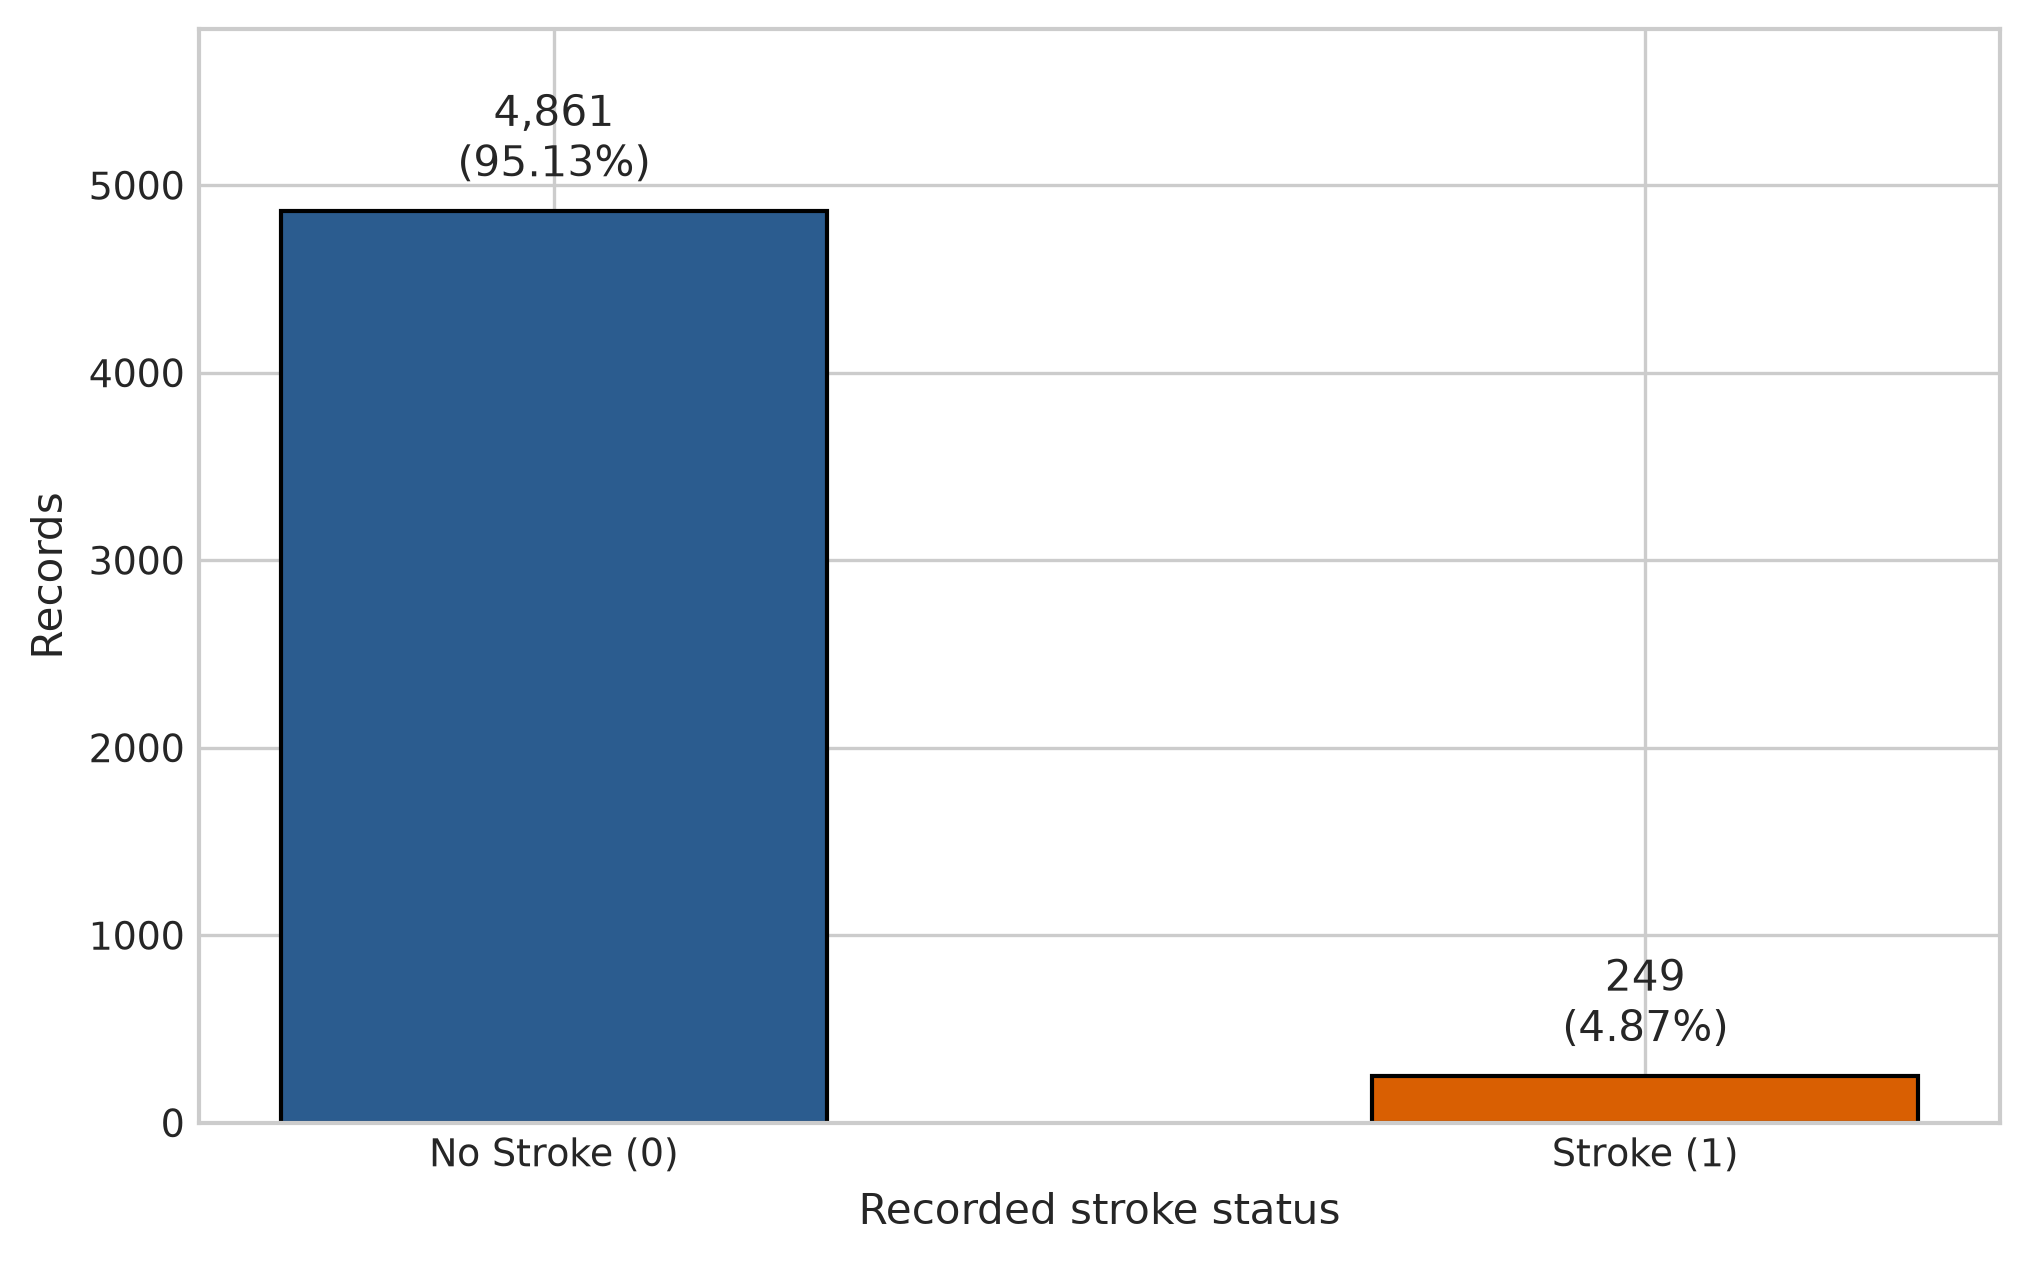

In [4]:
stroke_counts = df_raw.stroke.value_counts().reindex([0, 1], fill_value=0)
stroke_percentages = stroke_counts / n_raw * 100
raw_ratio = stroke_counts[0] / stroke_counts[1]
report_values.update(raw_no=int(stroke_counts[0]), raw_yes=int(stroke_counts[1]),
                     raw_no_pct=float(stroke_percentages[0]), raw_yes_pct=float(stroke_percentages[1]),
                     raw_ratio=float(raw_ratio))
for label, name in [(0, 'No Stroke'), (1, 'Stroke')]:
    print(f'{name} ({label}): {stroke_counts[label]:,} records ({stroke_percentages[label]:.2f}%)')
fig, ax = plt.subplots(figsize=(6.65, 4.1))
bars = ax.bar(['No Stroke (0)', 'Stroke (1)'], stroke_counts.values,
              color=['#2b5c8f', '#d95f02'], width=0.5, edgecolor='black')
for bar, count in zip(bars, stroke_counts.values):
    ax.annotate(f'{count:,}\n({count / n_raw * 100:.2f}%)',
                (bar.get_x() + bar.get_width()/2, count), xytext=(0, 5),
                textcoords='offset points', ha='center', va='bottom', fontsize=10)
ax.set(xlabel='Recorded stroke status', ylabel='Records', ylim=(0, stroke_counts.max()*1.20))
finish_figure(fig, f'Figure 1: Recorded Stroke Status — Raw Dataset (n = {n_raw:,})',
              'Counts and percentages refer to recorded stroke status, not overall health.')


### 1.3. Target Variable and Learning Task

`stroke = 1` indicates a recorded history of stroke (**249 records, 4.87%**); `stroke = 0` indicates no recorded stroke (**4,861 records, 95.13%**). No Stroke does not imply absence of hypertension, heart disease, or other conditions.

The raw class imbalance is **19.52:1**. A majority-class classifier would achieve 95.13% accuracy while detecting 0% of stroke records. The label supports supervised binary classification, but missing timestamps and follow-up information prevent validation of prospective future-event prediction.

This notebook performs **unsupervised PCA**: `stroke` is excluded from fitting and used only for descriptive group comparisons and plot coloring.


Field,Marker,Records,Percent
bmi,NaN (syntactic),201,3.93
smoking_status,Unknown (semantic),"1,544",30.22


Work type,Known,Unknown,Total,Unknown (%)
Govt_job,535,122,657,18.57
Never_worked,14,8,22,36.36
Private,2285,640,2925,21.88
Self-employed,663,156,819,19.05
children,69,618,687,89.96


stroke,Records,Missing BMI,Missing (%)
0,4861,161,3.31
1,249,40,16.06


Check,Flagged,Type
Age < 0,0,Domain
Glucose <= 0,0,Domain
Observed BMI <= 0,0,Domain
"Binary fields outside {0, 1}",0,Domain
Unexpected nominal category,0,Domain
Children work group and married,0,Review flag
Age < 18 and married,0,Review flag
Age >= 18 and children work group,0,Review flag


Exact duplicate rows: 0; excluding id: 0.


Variable,Q1,Q3,IQR fences,Flagged,Percent
age,25.00,61.00,-29.00–115.00,0,0.00
avg_glucose_level,77.25,114.09,21.98–169.36,627,12.27
bmi,23.50,33.10,9.10–47.50,110,2.24


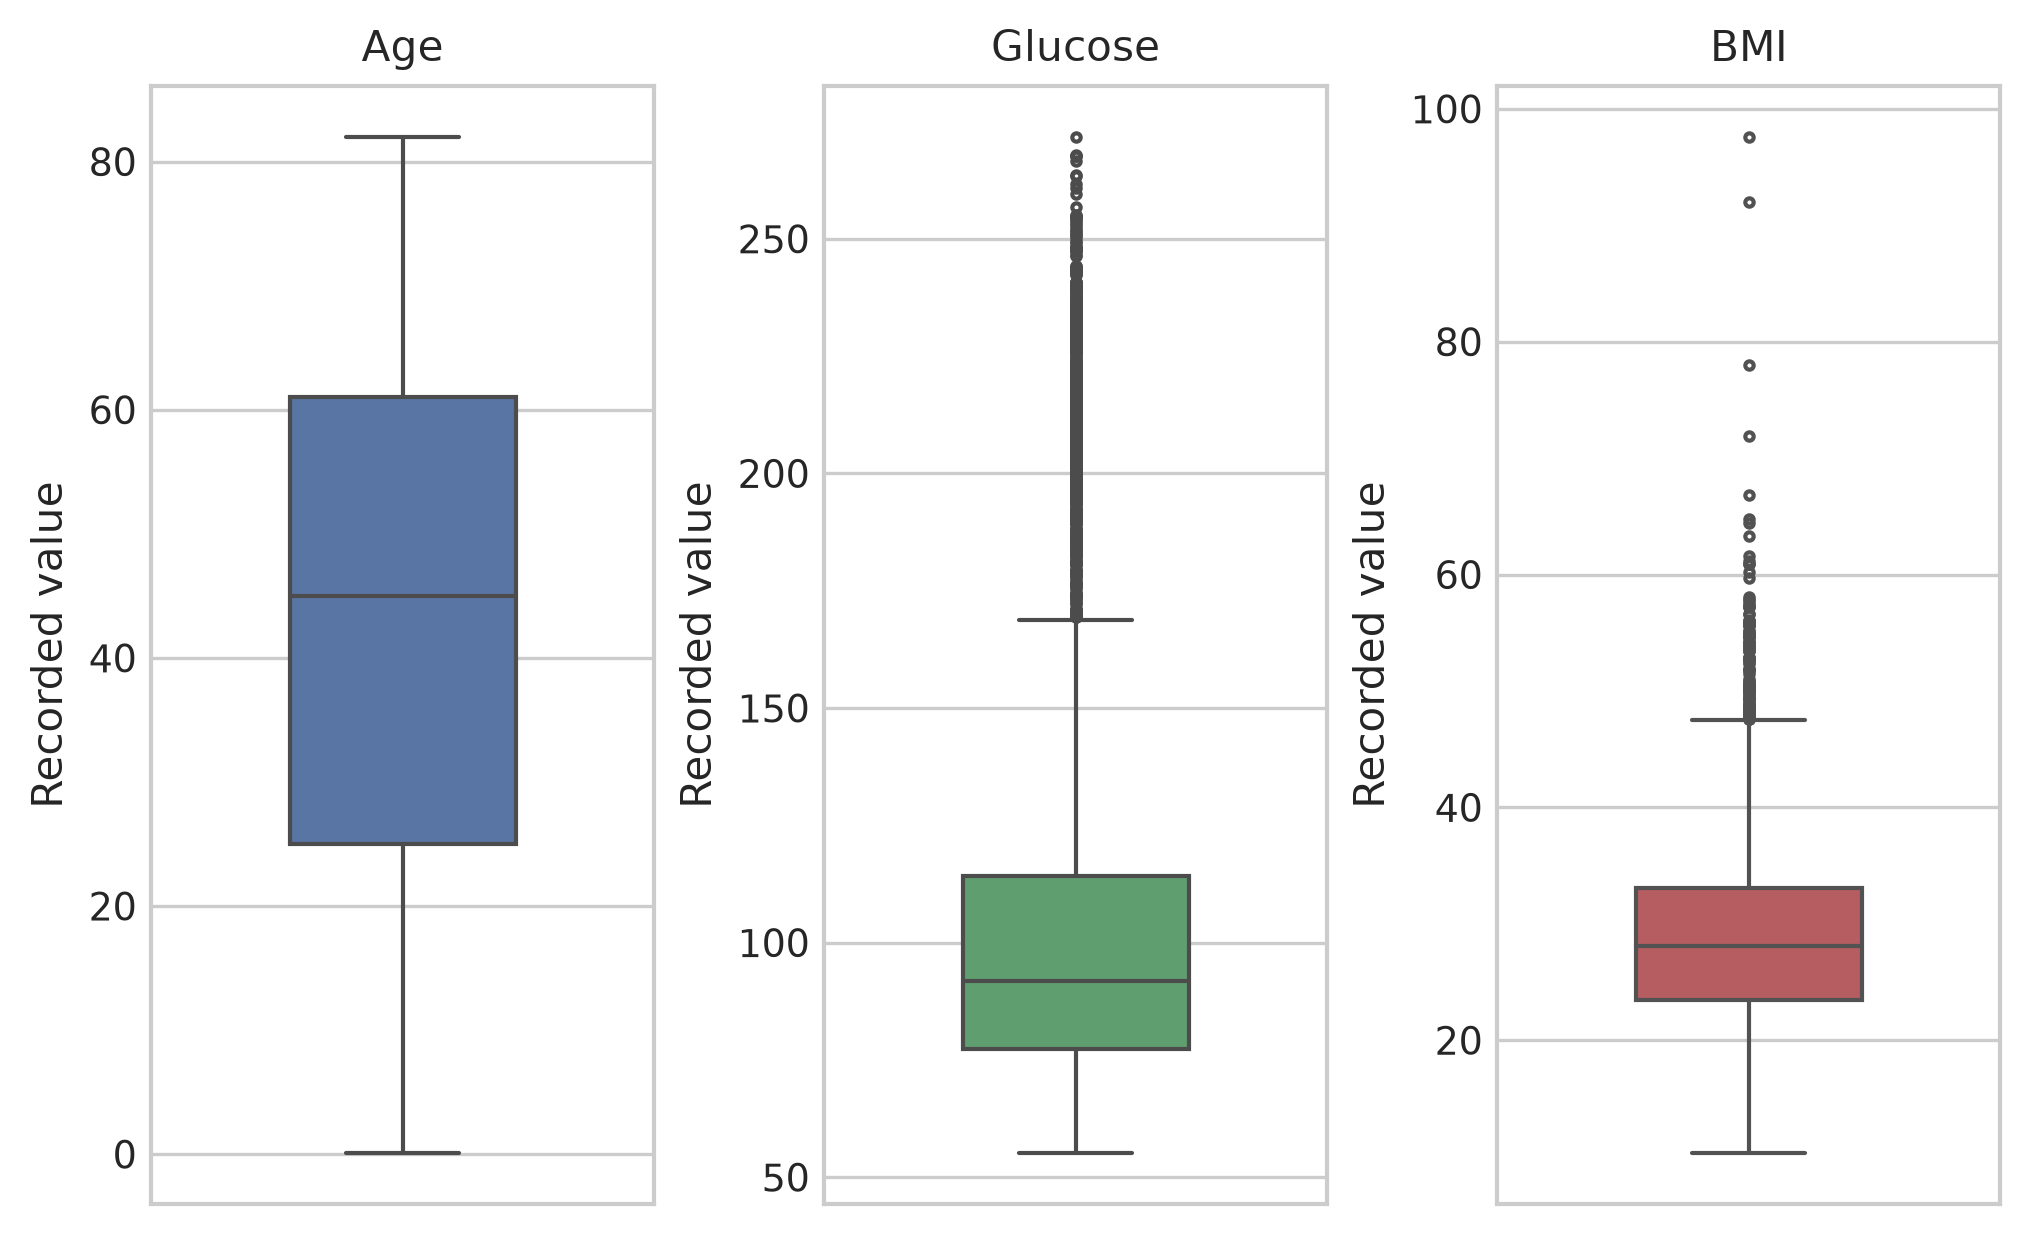

In [5]:
missing_bmi = int(df_raw.bmi.isna().sum())
unknown_smoke = int(df_raw.smoking_status.eq('Unknown').sum())
missing_markers = pd.DataFrame([
    ['bmi', 'NaN (syntactic)', f'{missing_bmi:,}', f'{100*missing_bmi/n_raw:.2f}'],
    ['smoking_status', 'Unknown (semantic)', f'{unknown_smoke:,}', f'{100*unknown_smoke/n_raw:.2f}'],
], columns=['Field', 'Marker', 'Records', 'Percent'])
show_table(missing_markers, 'Table 2. Missingness markers — raw data', [29, 31, 20, 20])

smoking_cross = pd.crosstab(df_raw.work_type, df_raw.smoking_status.eq('Unknown')).reindex(columns=[False, True], fill_value=0)
smoking_cross.columns = ['Known', 'Unknown']
smoking_cross['Total'] = smoking_cross.sum(axis=1)
smoking_cross['Unknown (%)'] = (100*smoking_cross.Unknown/smoking_cross.Total).map('{:.2f}'.format)
show_table(smoking_cross.reset_index().rename(columns={'work_type': 'Work type'}),
           'Table 3. Smoking-information availability by work type — raw data', [28, 17, 17, 17, 21])
bmi_by_target = df_raw.groupby('stroke').bmi.agg(Records='size', Observed='count')
bmi_by_target['Missing BMI'] = bmi_by_target.Records - bmi_by_target.Observed
bmi_by_target['Missing (%)'] = 100*bmi_by_target['Missing BMI']/bmi_by_target.Records
bmi_missing_display = bmi_by_target[['Records', 'Missing BMI', 'Missing (%)']].reset_index()
bmi_missing_display['Missing (%)'] = bmi_missing_display['Missing (%)'].map('{:.2f}'.format)
show_table(bmi_missing_display, 'Table 4. BMI missingness by target — raw data', [16, 28, 28, 28])

expected_levels = {
    'gender': {'Female', 'Male', 'Other'}, 'ever_married': {'No', 'Yes'},
    'work_type': {'Govt_job', 'Never_worked', 'Private', 'Self-employed', 'children'},
    'Residence_type': {'Rural', 'Urban'},
    'smoking_status': {'Unknown', 'formerly smoked', 'never smoked', 'smokes'},
}
binary_invalid = sum(int((~df_raw[c].isin([0, 1])).sum()) for c in ['hypertension', 'heart_disease', 'stroke'])
category_invalid = sum(int((~df_raw[c].isin(levels)).sum()) for c, levels in expected_levels.items())
checks = [
    ['Age < 0', int(df_raw.age.lt(0).sum()), 'Domain'],
    ['Glucose <= 0', int(df_raw.avg_glucose_level.le(0).sum()), 'Domain'],
    ['Observed BMI <= 0', int(df_raw.bmi.dropna().le(0).sum()), 'Domain'],
    ['Binary fields outside {0, 1}', binary_invalid, 'Domain'],
    ['Unexpected nominal category', category_invalid, 'Domain'],
    ['Children work group and married', int((df_raw.work_type.eq('children') & df_raw.ever_married.eq('Yes')).sum()), 'Review flag'],
    ['Age < 18 and married', int((df_raw.age.lt(18) & df_raw.ever_married.eq('Yes')).sum()), 'Review flag'],
    ['Age >= 18 and children work group', int((df_raw.age.ge(18) & df_raw.work_type.eq('children')).sum()), 'Review flag'],
]
domain_checks = pd.DataFrame(checks, columns=['Check', 'Flagged', 'Type'])
show_table(domain_checks, 'Table 5. Domain and cross-field checks — raw data', [64, 14, 22],
           'Cross-field rules screen for manual review; they do not automatically establish errors.')
duplicates_all = int(df_raw.duplicated().sum())
duplicates_no_id = int(df_raw.drop(columns='id').duplicated().sum())
print(f'Exact duplicate rows: {duplicates_all}; excluding id: {duplicates_no_id}.')

outlier_records = []
for col in numeric_features:
    s = df_raw[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    count = int(((s < lo) | (s > hi)).sum())
    outlier_records.append([col, f'{q1:.2f}', f'{q3:.2f}', f'{lo:.2f}–{hi:.2f}', count, f'{100*count/len(s):.2f}'])
outliers = pd.DataFrame(outlier_records, columns=['Variable', 'Q1', 'Q3', 'IQR fences', 'Flagged', 'Percent'])
show_table(outliers, 'Table 5 (continued). IQR outlier screen — raw observed values', [28, 11, 11, 25, 12, 13],
           'BMI percentage uses observed BMI values; outlier flags do not verify recording errors.')
fig, axes = plt.subplots(1, 3, figsize=(6.65, 4.0))
for ax, col, label, color in zip(axes, numeric_features, ['Age', 'Glucose', 'BMI'], ['#4c72b0', '#55a868', '#c44e52']):
    sns.boxplot(y=df_raw[col], ax=ax, color=color, width=0.45, fliersize=2)
    ax.set(title=label, xlabel='', ylabel='Recorded value')
finish_figure(fig, 'Figure 2: Numerical Distributions — Raw Dataset',
              'Boxplots use observed values. Separate axes preserve the original measurement scales.')
report_values.update(missing_bmi=missing_bmi, missing_bmi_pct=100*missing_bmi/n_raw,
    unknown_smoke=unknown_smoke, unknown_pct=100*unknown_smoke/n_raw,
    child_unknown=int(smoking_cross.loc['children', 'Unknown']), child_n=int(smoking_cross.loc['children', 'Total']),
    child_unknown_pct=100*smoking_cross.loc['children', 'Unknown']/smoking_cross.loc['children', 'Total'],
    missing_yes_pct=float(bmi_by_target.loc[1, 'Missing (%)']), missing_no_pct=float(bmi_by_target.loc[0, 'Missing (%)']),
    duplicates_all=duplicates_all, duplicates_no_id=duplicates_no_id,
    age_outliers=int(outliers.iloc[0]['Flagged']), glucose_outliers=int(outliers.iloc[1]['Flagged']),
    bmi_outliers=int(outliers.iloc[2]['Flagged']))


### 1.4. Data Quality Assessment

Tables 2–5 distinguish **syntactic missingness** in BMI (201 NaNs, 3.93%) from **semantic missingness** in smoking status (`Unknown`: 1,544 records, 30.22%). Smoking information is unavailable for 618 of 687 children-group records (89.96%). This is an observed association, not evidence of a particular hospital intake process.

BMI missingness differs by target: **16.06% in stroke records versus 3.31% in no-stroke records**. This warrants attention when interpreting imputed BMI, but does not by itself identify the missing-data mechanism.

There are 0 exact duplicate rows and 0 when `id` is excluded. This does not prove that every row represents a different person. Domain checks identify invalid codes or non-positive measurements; cross-field flags are prompts for review rather than automatic errors.

The IQR screen flags 0 age, 627 glucose, and 110 observed BMI values (Table 5, continued). With $\mathrm{IQR}=Q_3-Q_1$, values outside $[Q_1-1.5\,\mathrm{IQR},\ Q_3+1.5\,\mathrm{IQR}]$ are statistical outliers, **not verified recording errors**.

Extreme observations and missing-value handling can alter the sample mean, variance, and covariance, potentially affecting PCA directions. Cleaning choices therefore require explicit justification and before/after assessment (DM 2 [2, pp.11–16]).


In [6]:
df_clean = df_raw.drop(columns='id').copy()
other_count = int(df_clean.gender.eq('Other').sum())
variance_stages = [['Raw observed values', int(df_raw.bmi.count()), df_raw.bmi.var(ddof=1)]]
df_clean = df_clean.loc[df_clean.gender.ne('Other')].reset_index(drop=True)
variance_stages.append(['After excluding Other', int(df_clean.bmi.count()), df_clean.bmi.var(ddof=1)])
bmi_median = float(df_clean.bmi.median())
imputed_count = int(df_clean.bmi.isna().sum())
df_clean['bmi'] = df_clean.bmi.fillna(bmi_median)
variance_stages.append(['After median imputation', int(df_clean.bmi.count()), df_clean.bmi.var(ddof=1)])
BMI_CAP = 60.0
cap_mask = df_clean.bmi.gt(BMI_CAP)
capped_count = int(cap_mask.sum())
capped_no_stroke = int(df_clean.loc[cap_mask, 'stroke'].eq(0).sum())
df_clean['bmi'] = df_clean.bmi.clip(upper=BMI_CAP)
variance_stages.append(['After BMI cap', int(df_clean.bmi.count()), df_clean.bmi.var(ddof=1)])
print(f'\nRecords: {len(df_raw):,} -> {len(df_clean):,}; excluded Other: {other_count}.')
print(f'BMI imputation: {imputed_count} values at median {bmi_median:.2f}.')
print(f'BMI cap at {BMI_CAP:.1f}: {capped_count} records; No Stroke: {capped_no_stroke}.')
counts = pd.DataFrame([
    ['Records', len(df_raw), len(df_clean)],
    ['Non-null BMI', df_raw.bmi.count(), df_clean.bmi.count()],
    ['Missing BMI', df_raw.bmi.isna().sum(), df_clean.bmi.isna().sum()],
    ['Gender = Other', df_raw.gender.eq('Other').sum(), df_clean.gender.eq('Other').sum()],
    ['Smoking = Unknown', df_raw.smoking_status.eq('Unknown').sum(), df_clean.smoking_status.eq('Unknown').sum()],
    ['BMI > 60', df_raw.bmi.gt(BMI_CAP).sum(), df_clean.bmi.gt(BMI_CAP).sum()],
], columns=['Measure', 'Before', 'After'])
for c in ['Before', 'After']: counts[c] = counts[c].map('{:,}'.format)
show_table(counts, 'Table 6a. Cleaning counts — raw versus cleaned data', [52, 24, 24])
comparison = []
for col, name in zip(numeric_features, ['Age', 'Glucose', 'BMI']):
    for stage, frame in [('Before', df_raw), ('After', df_clean)]:
        s = frame[col].dropna()
        comparison.append([name, stage, f'{s.min():.2f}–{s.max():.2f}', f'{s.mean():.4f}', f'{s.std(ddof=1):.4f}', f'{s.var(ddof=1):.4f}'])
show_table(pd.DataFrame(comparison, columns=['Variable', 'Stage', 'Range', 'Mean', 'SD', 'Variance']),
    'Table 6b. Numerical distributions — raw versus cleaned data', [14, 13, 22, 16, 16, 19],
    f'Before-cleaning BMI uses {df_raw.bmi.count():,} observed values. SD and variance use ddof=1.')
variance_df = pd.DataFrame(variance_stages, columns=['Stage', 'Non-null BMI', 'Sample variance'])
variance_df['Sample variance'] = variance_df['Sample variance'].map('{:.4f}'.format)
show_table(variance_df, 'Table 7. Stepwise BMI variance — cleaning stages', [52, 22, 26])
report_values.update(n_clean=len(df_clean), other_count=other_count, bmi_median=bmi_median,
    imputed_count=imputed_count, capped_count=capped_count, capped_no_stroke=capped_no_stroke,
    bmi_var_raw=float(variance_stages[0][2]), bmi_var_drop=float(variance_stages[1][2]),
    bmi_var_impute=float(variance_stages[2][2]), bmi_var_cap=float(variance_stages[3][2]),
    bmi_cap=BMI_CAP)



Records: 5,110 -> 5,109; excluded Other: 1.
BMI imputation: 201 values at median 28.10.
BMI cap at 60.0: 13 records; No Stroke: 13.


Measure,Before,After
Records,"5,110","5,109"
Non-null BMI,"4,909","5,109"
Missing BMI,201,0
Gender = Other,1,0
Smoking = Unknown,"1,544","1,544"
BMI > 60,13,0


Variable,Stage,Range,Mean,SD,Variance
Age,Before,0.08–82.00,43.2266,22.6126,511.3318
Age,After,0.08–82.00,43.2300,22.6136,511.3738
Glucose,Before,55.12–271.74,106.1477,45.2836,2050.6008
Glucose,After,55.12–271.74,106.1404,45.2850,2050.7316
BMI,Before,10.30–97.60,28.8932,7.8541,61.6864
BMI,After,10.30–60.00,28.8391,7.5624,57.1903


Stage,Non-null BMI,Sample variance
Raw observed values,4909,61.6864
After excluding Other,4908,61.6903
After median imputation,5109,59.2867
After BMI cap,5109,57.1903


### 1.5. Cleaning Decisions and Their Effects

The identifier is excluded from the analytical inputs. Excluding the 1 `Other` gender record is a pragmatic choice for this analysis's binary encoding, **not a judgment that the value is erroneous**; it reduces category representation and leaves 5,109 records.

The 201 missing BMI values are filled with the median, **28.10**. The median is less sensitive to extremes than the mean, but single-value imputation creates a point concentration and changes variance and correlations. Smoking `Unknown` is retained to avoid inventing information for 30.22% of records.

BMI above **60.0** is capped as a heuristic to limit extreme squared leverage: **13 records**, all 13 labeled No Stroke, are affected. This is not an absolute physiological boundary and the capped observations have not been verified as errors.

Table 7 separates BMI variance changes: **61.6864 → 61.6903 → 59.2867 → 57.1903**. Both imputation and capping contribute to the reduction. Age and glucose measurements are not directly modified, but their aggregate statistics shift slightly because one record is excluded (Table 6b).


In [7]:
print('Integration inspection — raw CSV schema:')
print(f' - id: {df_raw.id.nunique():,} unique internal record identifiers.')
print(' - No external registry mapping is supplied.')
print(' - Residence_type: ' + ', '.join(sorted(df_raw.Residence_type.unique())) + '; not a geographic key.')
print(' - No timestamp, hospital/site key, or linked table is supplied.')
print('Integration status: investigated; not performed.')


Integration inspection — raw CSV schema:
 - id: 5,110 unique internal record identifiers.
 - No external registry mapping is supplied.
 - Residence_type: Rural, Urban; not a geographic key.
 - No timestamp, hospital/site key, or linked table is supplied.
Integration status: investigated; not performed.


### 1.6. Data Integration

Additional clinical or environmental records could provide useful context, but no compatible linked source is supplied. The raw `id` is an internal identifier without an external registry mapping; `Residence_type` gives only Rural/Urban categories, not geographic keys. The CSV also lacks timestamps and hospital/site identifiers.

Integration is therefore **investigated but not performed**, consistent with TD1-PCA's conditional “if applicable” requirement [1]. Joining external information without defensible linkage could create misleading associations. No specific privacy-law compliance process or legal impossibility is inferred from this schema.


In [8]:
X_unencoded = df_clean.drop(columns='stroke')
y = df_clean.stroke.copy()
X_trans = X_unencoded.copy()
for col, mapping in {
    'gender': {'Female': 0, 'Male': 1},
    'ever_married': {'No': 0, 'Yes': 1},
    'Residence_type': {'Rural': 0, 'Urban': 1},
}.items():
    X_trans[col] = X_trans[col].map(mapping)
X_encoded = pd.get_dummies(X_trans, columns=['work_type', 'smoking_status'], drop_first=False, dtype=int)
feature_names = list(X_encoded.columns)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)
df_scaled = pd.DataFrame(X_scaled, columns=feature_names, index=X_encoded.index)
n_samples, d_encoded = X_scaled.shape
scaled_means = X_scaled.mean(axis=0)
scaled_variances = X_scaled.var(axis=0, ddof=0)
assert np.isfinite(X_scaled).all()
assert np.allclose(scaled_means, 0, atol=1e-12)
assert np.allclose(scaled_variances, 1, atol=1e-12)
print(f'Standardized matrix: {n_samples:,} records x {d_encoded} encoded inputs; stroke excluded.')
print('Standardization verification (population variance, ddof=0):')
for name, mean, variance in zip(feature_names, scaled_means, scaled_variances):
    print(f' {name:31s} mean={mean:+.2e}  variance={variance:.4f}')
rare_name = 'work_type_Never_worked'
rare_index = feature_names.index(rare_name)
rare_count = int(X_encoded[rare_name].sum())
rare_active_z = float(X_scaled[X_encoded[rare_name].eq(1), rare_index][0])
print(f'Never_worked: {rare_count} records; active standardized value = {rare_active_z:.4f}.')
group_column_count = sum(c.startswith(('work_type_', 'smoking_status_')) for c in feature_names)
report_values.update(d=d_encoded, rare_count=rare_count, rare_active_z=rare_active_z,
    group_columns=group_column_count, group_variance_pct=100*group_column_count/d_encoded,
    glucose_variance=float(df_clean.avg_glucose_level.var(ddof=1)))


Standardized matrix: 5,109 records x 17 encoded inputs; stroke excluded.
Standardization verification (population variance, ddof=0):
 gender                          mean=+4.73e-17  variance=1.0000
 age                             mean=+7.23e-17  variance=1.0000
 hypertension                    mean=-6.12e-17  variance=1.0000
 heart_disease                   mean=-6.95e-17  variance=1.0000
 ever_married                    mean=+9.18e-17  variance=1.0000
 Residence_type                  mean=-8.62e-17  variance=1.0000
 avg_glucose_level               mean=-1.61e-16  variance=1.0000
 bmi                             mean=+1.22e-16  variance=1.0000
 work_type_Govt_job              mean=+4.17e-17  variance=1.0000
 work_type_Never_worked          mean=-1.60e-17  variance=1.0000
 work_type_Private               mean=-5.01e-17  variance=1.0000
 work_type_Self-employed         mean=+3.69e-17  variance=1.0000
 work_type_children              mean=-2.78e-18  variance=1.0000
 smoking_status_Unknow

### 1.7. Why Z-score Standardization Is Appropriate for This Dataset

Binary mapping preserves one column for each dichotomous variable. Full one-hot encoding represents work type and smoking status without imposing a category order, producing **17 input columns**; `stroke` is kept separate.

Following DM 3 [4, p.27], covariance-based PCA uses mean-centered data. Scaling is a separate choice: cleaned glucose sample variance is 2050.73, whereas binary-feature variance is approximately bounded by 0.25, a disparity exceeding 8,000 times. Z-score scaling reduces domination by differing measurement units:

$$z_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j},\qquad
\mu_j=\frac1n\sum_i x_{ij},\qquad
\sigma_j^2=\frac1n\sum_i(x_{ij}-\mu_j)^2.$$

`StandardScaler` uses denominator $n$ (ddof=0). All 17 means are approximately zero and population variances one. Min–max scaling, $(x-x_{\min})/(x_{\max}-x_{\min})$, is another option (DM 2 [2, p.19]), but its bounds depend on observed extremes. Neither scaling method makes PCA insensitive to outliers.

Encoding also changes weighting: work type (five columns) and smoking status (four) contribute **9/17 = 52.94%** of total standardized variance before PCA. Equal weight per encoded column is not equal weight per original variable.

The rare `work_type_Never_worked` dummy occurs 22 times and reaches **15.21** when active. Its PC7 weight is **0.78** (Figure 8), illustrating how standardization can emphasize rare categories.


In [9]:
numerical_summary = pd.DataFrame([
    [col, f'{df_clean[col].mean():.4f}', f'{df_clean[col].std(ddof=1):.4f}', f'{df_clean[col].var(ddof=1):.4f}']
    for col in numeric_features], columns=['Variable', 'Mean', 'SD', 'Variance'])
show_table(numerical_summary, 'Table 8. Numerical statistics — cleaned data', [34, 22, 22, 22],
           'SD and variance use ddof=1. Ranges and the raw comparison are in Table 6b.')
cat_cols = ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
mode_records, test_records, rate_records = [], [], []
chi_results, category_rates = {}, {}
for col in cat_cols:
    s = df_clean[col]; mode = s.mode().iloc[0]; freq = int(s.eq(mode).sum())
    mode_records.append([col, s.nunique(), str(mode), f'{freq:,} ({100*freq/len(s):.1f}%)'])
    table = pd.crosstab(s, y).reindex(columns=[0, 1], fill_value=0)
    chi2, p_value, dof, expected = chi2_contingency(table, correction=True)
    chi_results[col] = {'chi2': float(chi2), 'p': float(p_value), 'df': int(dof), 'min_expected': float(expected.min())}
    test_records.append([col, f'{chi2:.4f}', dof, f'{p_value:.4e}', f'{expected.min():.2f}'])
    for category, row in table.iterrows():
        total = int(row.sum()); positives = int(row[1]); rate = 100*positives/total
        category_rates[f'{col}:{category}'] = rate
        rate_records.append([f'{col}: {category}', f'{total:,}', positives, f'{rate:.2f}'])
show_table(pd.DataFrame(mode_records, columns=['Feature', 'Levels', 'Mode', 'Mode count (%)']),
           'Table 9a. Categorical modes — cleaned data', [29, 12, 29, 30])
show_table(pd.DataFrame(test_records, columns=['Feature', 'Chi2', 'df', 'p-value', 'Min expected']),
           'Table 9b. Chi-square association tests — cleaned data', [28, 17, 8, 25, 22],
           'Yates continuity correction applies to the 2 x 2 tables; other tables use Pearson chi-square.')
show_table(pd.DataFrame(rate_records, columns=['Feature / category', 'Records', 'Stroke records', 'Stroke (%)']),
           'Table 10. Category-specific stroke rates — cleaned data', [46, 18, 18, 18])
report_values.update(heart_yes_rate=category_rates['heart_disease:1'], heart_no_rate=category_rates['heart_disease:0'],
    hypertension_yes_rate=category_rates['hypertension:1'], hypertension_no_rate=category_rates['hypertension:0'],
    work_min_expected=chi_results['work_type']['min_expected'], gender_p=chi_results['gender']['p'],
    residence_p=chi_results['Residence_type']['p'])


Variable,Mean,SD,Variance
age,43.2300,22.6136,511.3738
avg_glucose_level,106.1404,45.2850,2050.7316
bmi,28.8391,7.5624,57.1903


Feature,Levels,Mode,Mode count (%)
gender,2,Female,"2,994 (58.6%)"
hypertension,2,0,"4,611 (90.3%)"
heart_disease,2,0,"4,833 (94.6%)"
ever_married,2,Yes,"3,353 (65.6%)"
work_type,5,Private,"2,924 (57.2%)"
Residence_type,2,Urban,"2,596 (50.8%)"
smoking_status,4,never smoked,"1,892 (37.0%)"


Feature,Chi2,df,p-value,Min expected
gender,0.3400,1,5.5983e-01,103.08
hypertension,81.5731,1,1.6889e-19,24.27
heart_disease,90.2294,1,2.1208e-21,13.45
ever_married,58.8678,1,1.6863e-14,85.58
work_type,49.1591,4,5.4090e-10,1.07
Residence_type,1.0750,1,2.9983e-01,122.48
smoking_status,29.2257,3,2.0077e-06,38.45


Feature / category,Records,Stroke records,Stroke (%)
gender: Female,"2,994",141,4.71
gender: Male,"2,115",108,5.11
hypertension: 0,"4,611",183,3.97
hypertension: 1,498,66,13.25
heart_disease: 0,"4,833",202,4.18
heart_disease: 1,276,47,17.03
ever_married: No,"1,756",29,1.65
ever_married: Yes,"3,353",220,6.56
work_type: Govt_job,657,33,5.02
work_type: Never_worked,22,0,0.00


### 1.8. Statistical Measures and Hypothesis Testing

For a numerical variable, the sample mean is the **empirical first raw moment**, not the first central moment (DM 2.5 and DM 3 [3,4]):

$$\bar x=\frac1n\sum_i x_i,\qquad
s^2=\frac1{n-1}\sum_i(x_i-\bar x)^2,\qquad s=\sqrt{s^2}.$$

Tables 8–10 summarize cleaned data. Means alone do not describe skewed distributions or mixtures of pediatric and adult observations; a mean glucose or BMI is not a diagnosis or a complete population profile. Nominal categories are summarized by frequencies, modes, and contingency tables, not numerical means.

Pearson's independence statistic uses observed counts $O_{rc}$ and expected counts $E_{rc}=N_{r\cdot}N_{\cdot c}/n$:

$$\chi^2=\sum_{r,c}\frac{(O_{rc}-E_{rc})^2}{E_{rc}},\qquad df=(R-1)(C-1).$$

For the $2\times2$ tables, the computation applies Yates' continuity correction:

$$\chi_Y^2=\sum_{r,c}\frac{\max(|O_{rc}-E_{rc}|-0.5,\,0)^2}{E_{rc}}.$$

Stroke prevalence is **17.03% with heart disease versus 4.18% without**, and **13.25% with hypertension versus 3.97% without**. The associated small p-values indicate associations in this dataset, not causation or confounding-adjusted effects.

Work type has a minimum expected count of **1.07**, so its asymptotic result should be read with the sparse-cell limitation. For gender ($p=0.560$) and residence type ($p=0.300$), there is insufficient evidence to reject independence at 0.05; this does not prove identical prevalence. These exploratory tests are unadjusted for age, other covariates, or multiple testing.


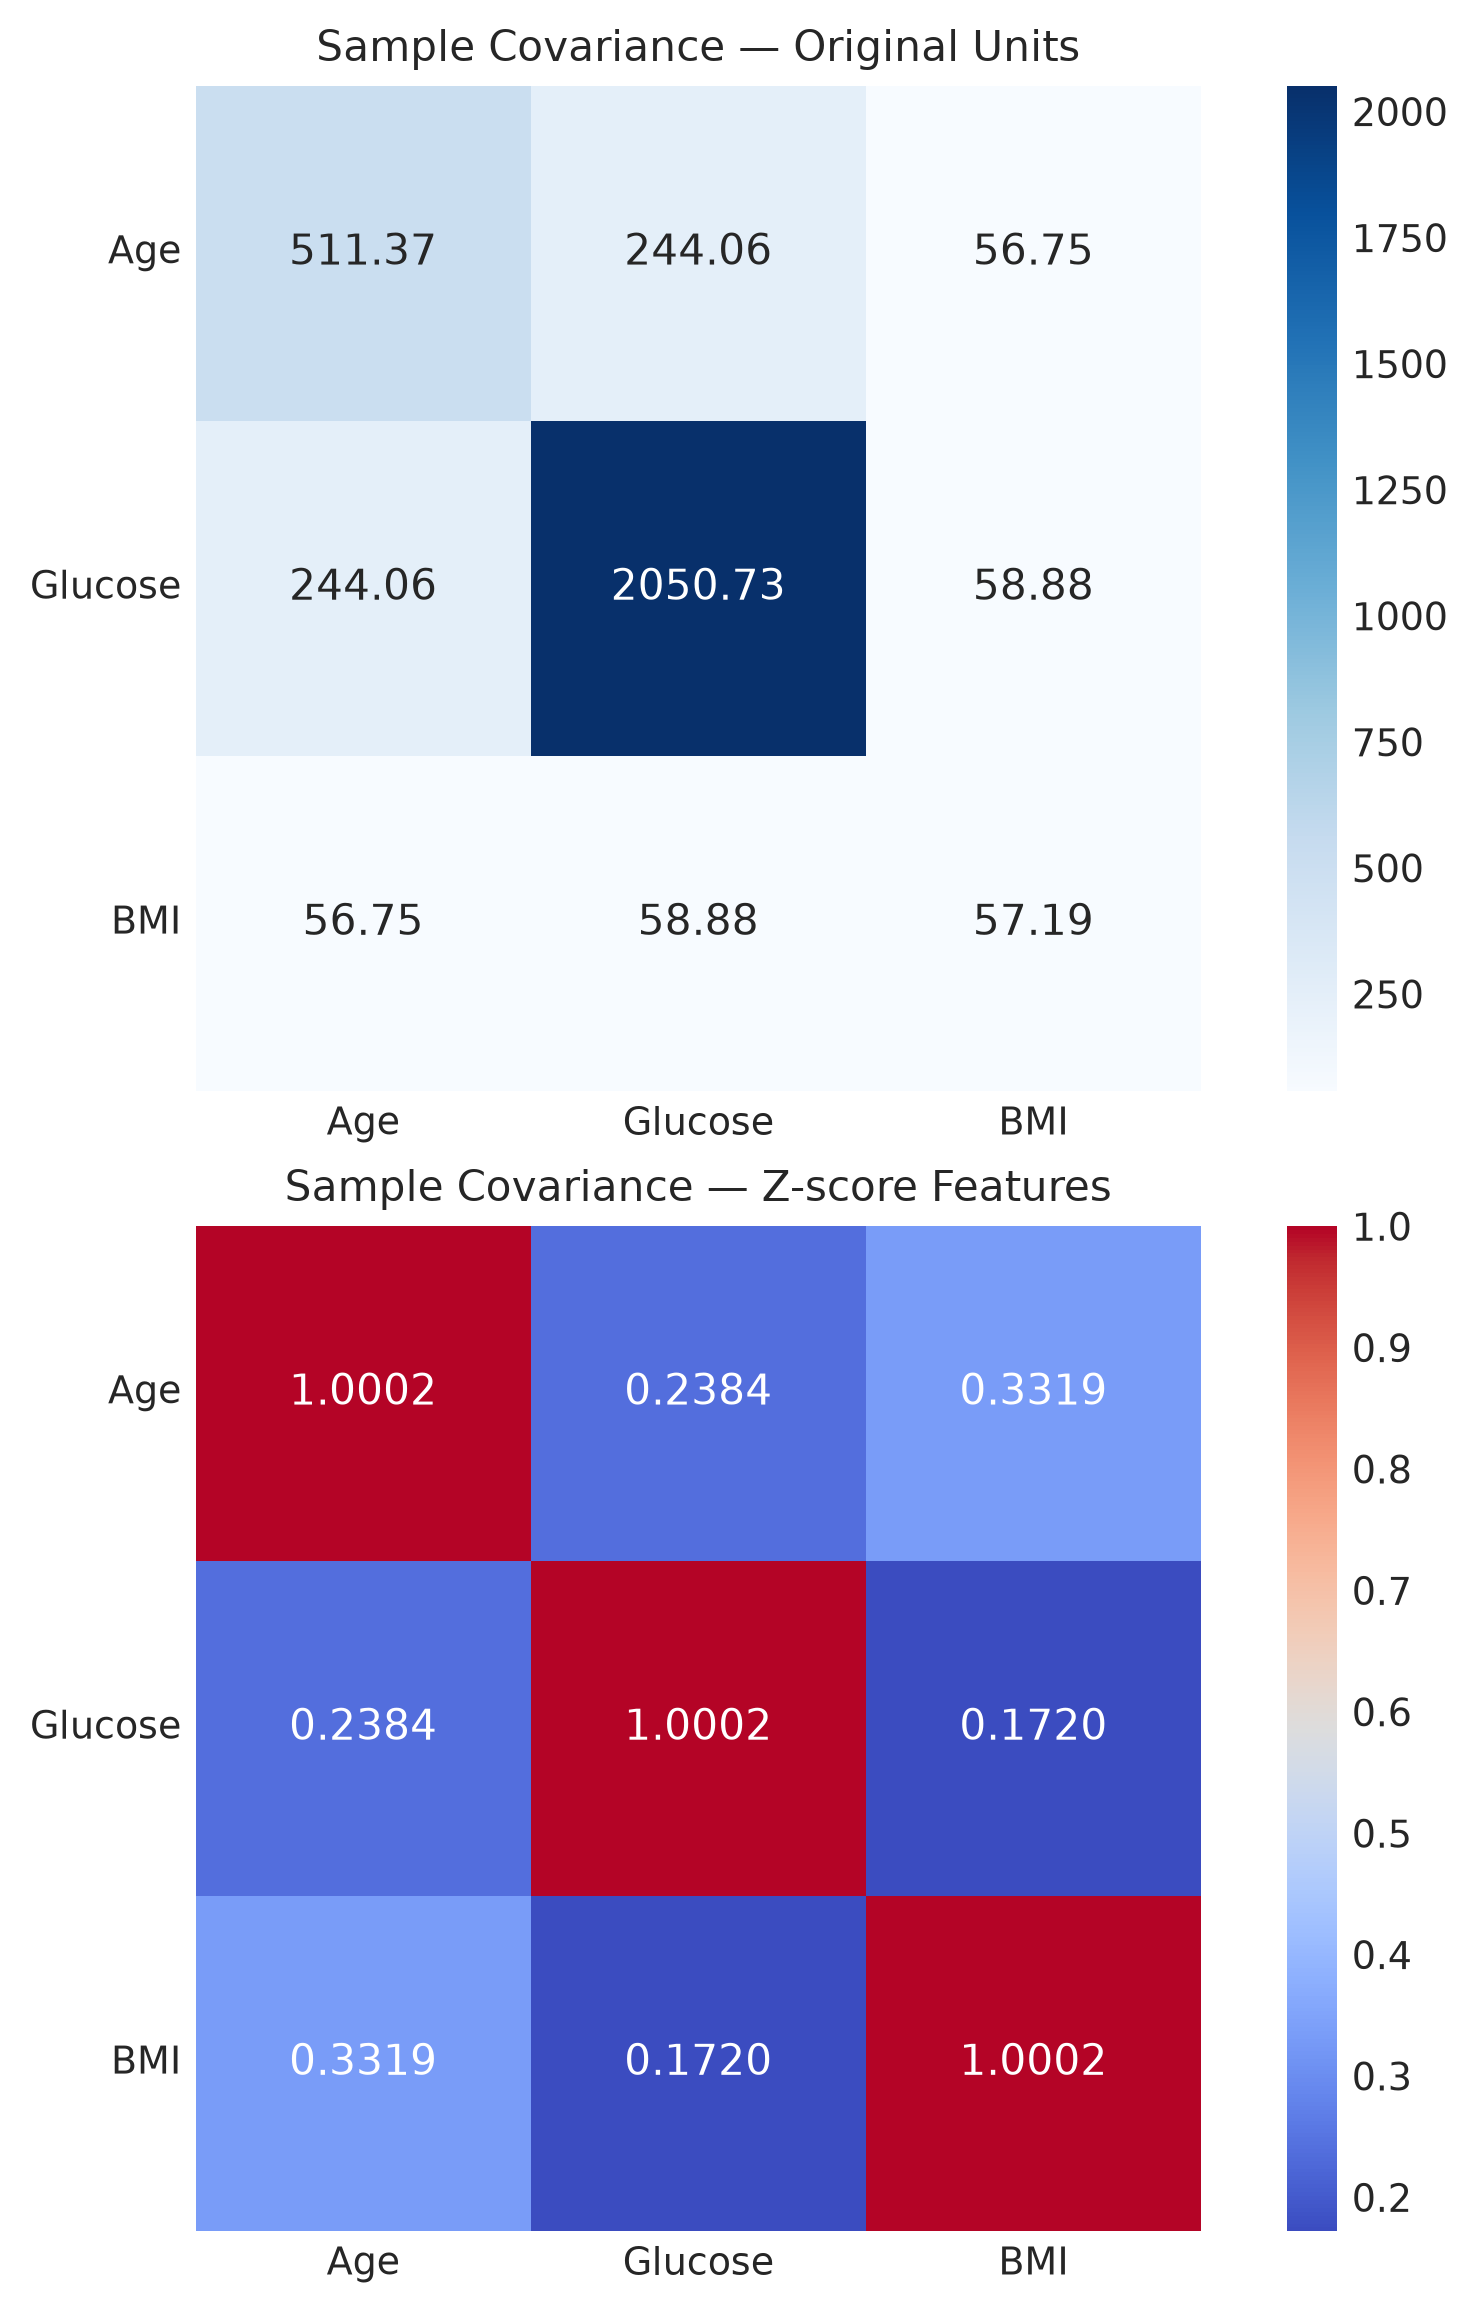

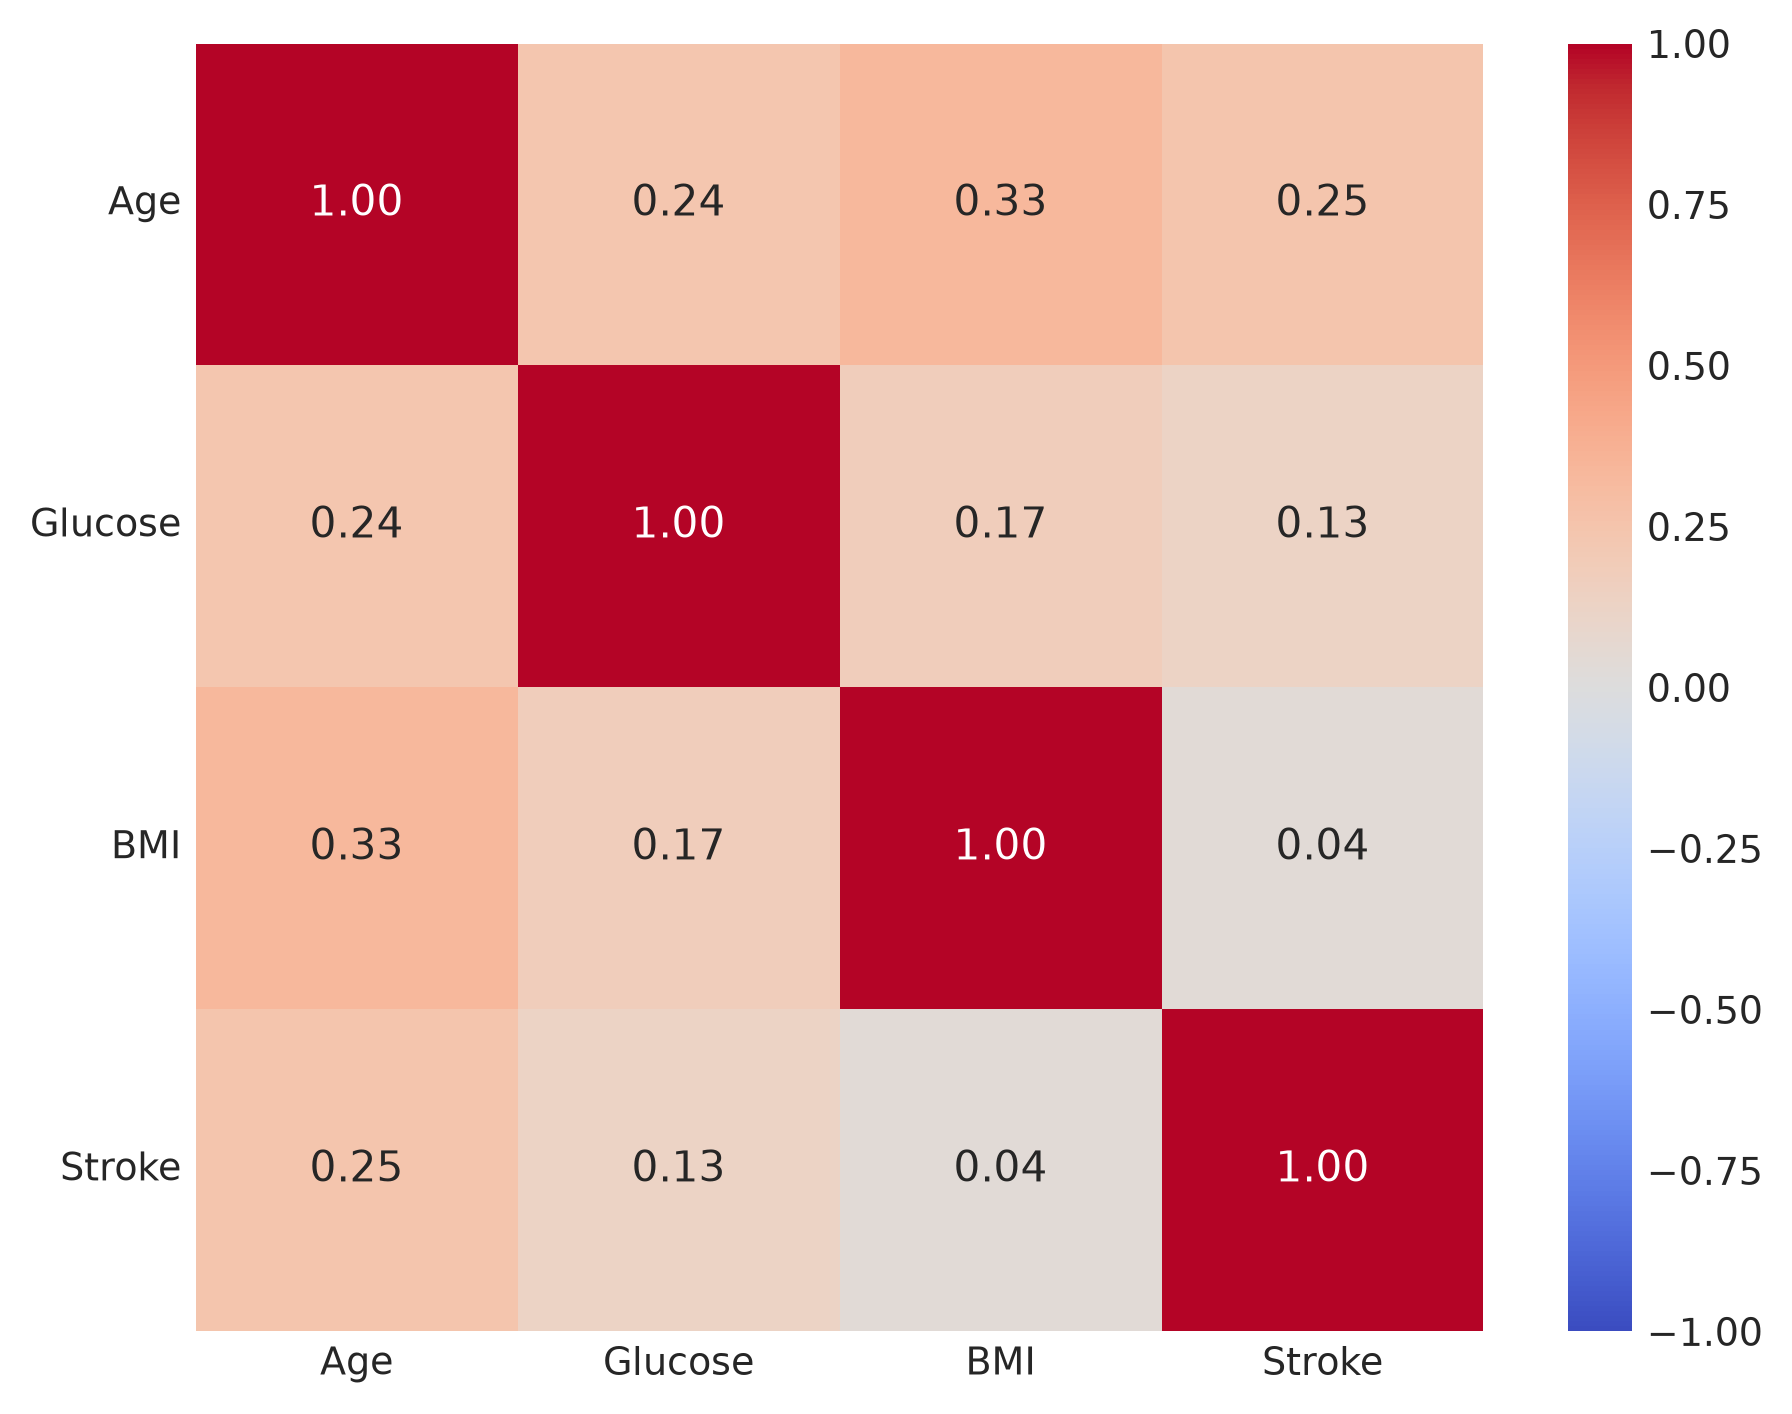

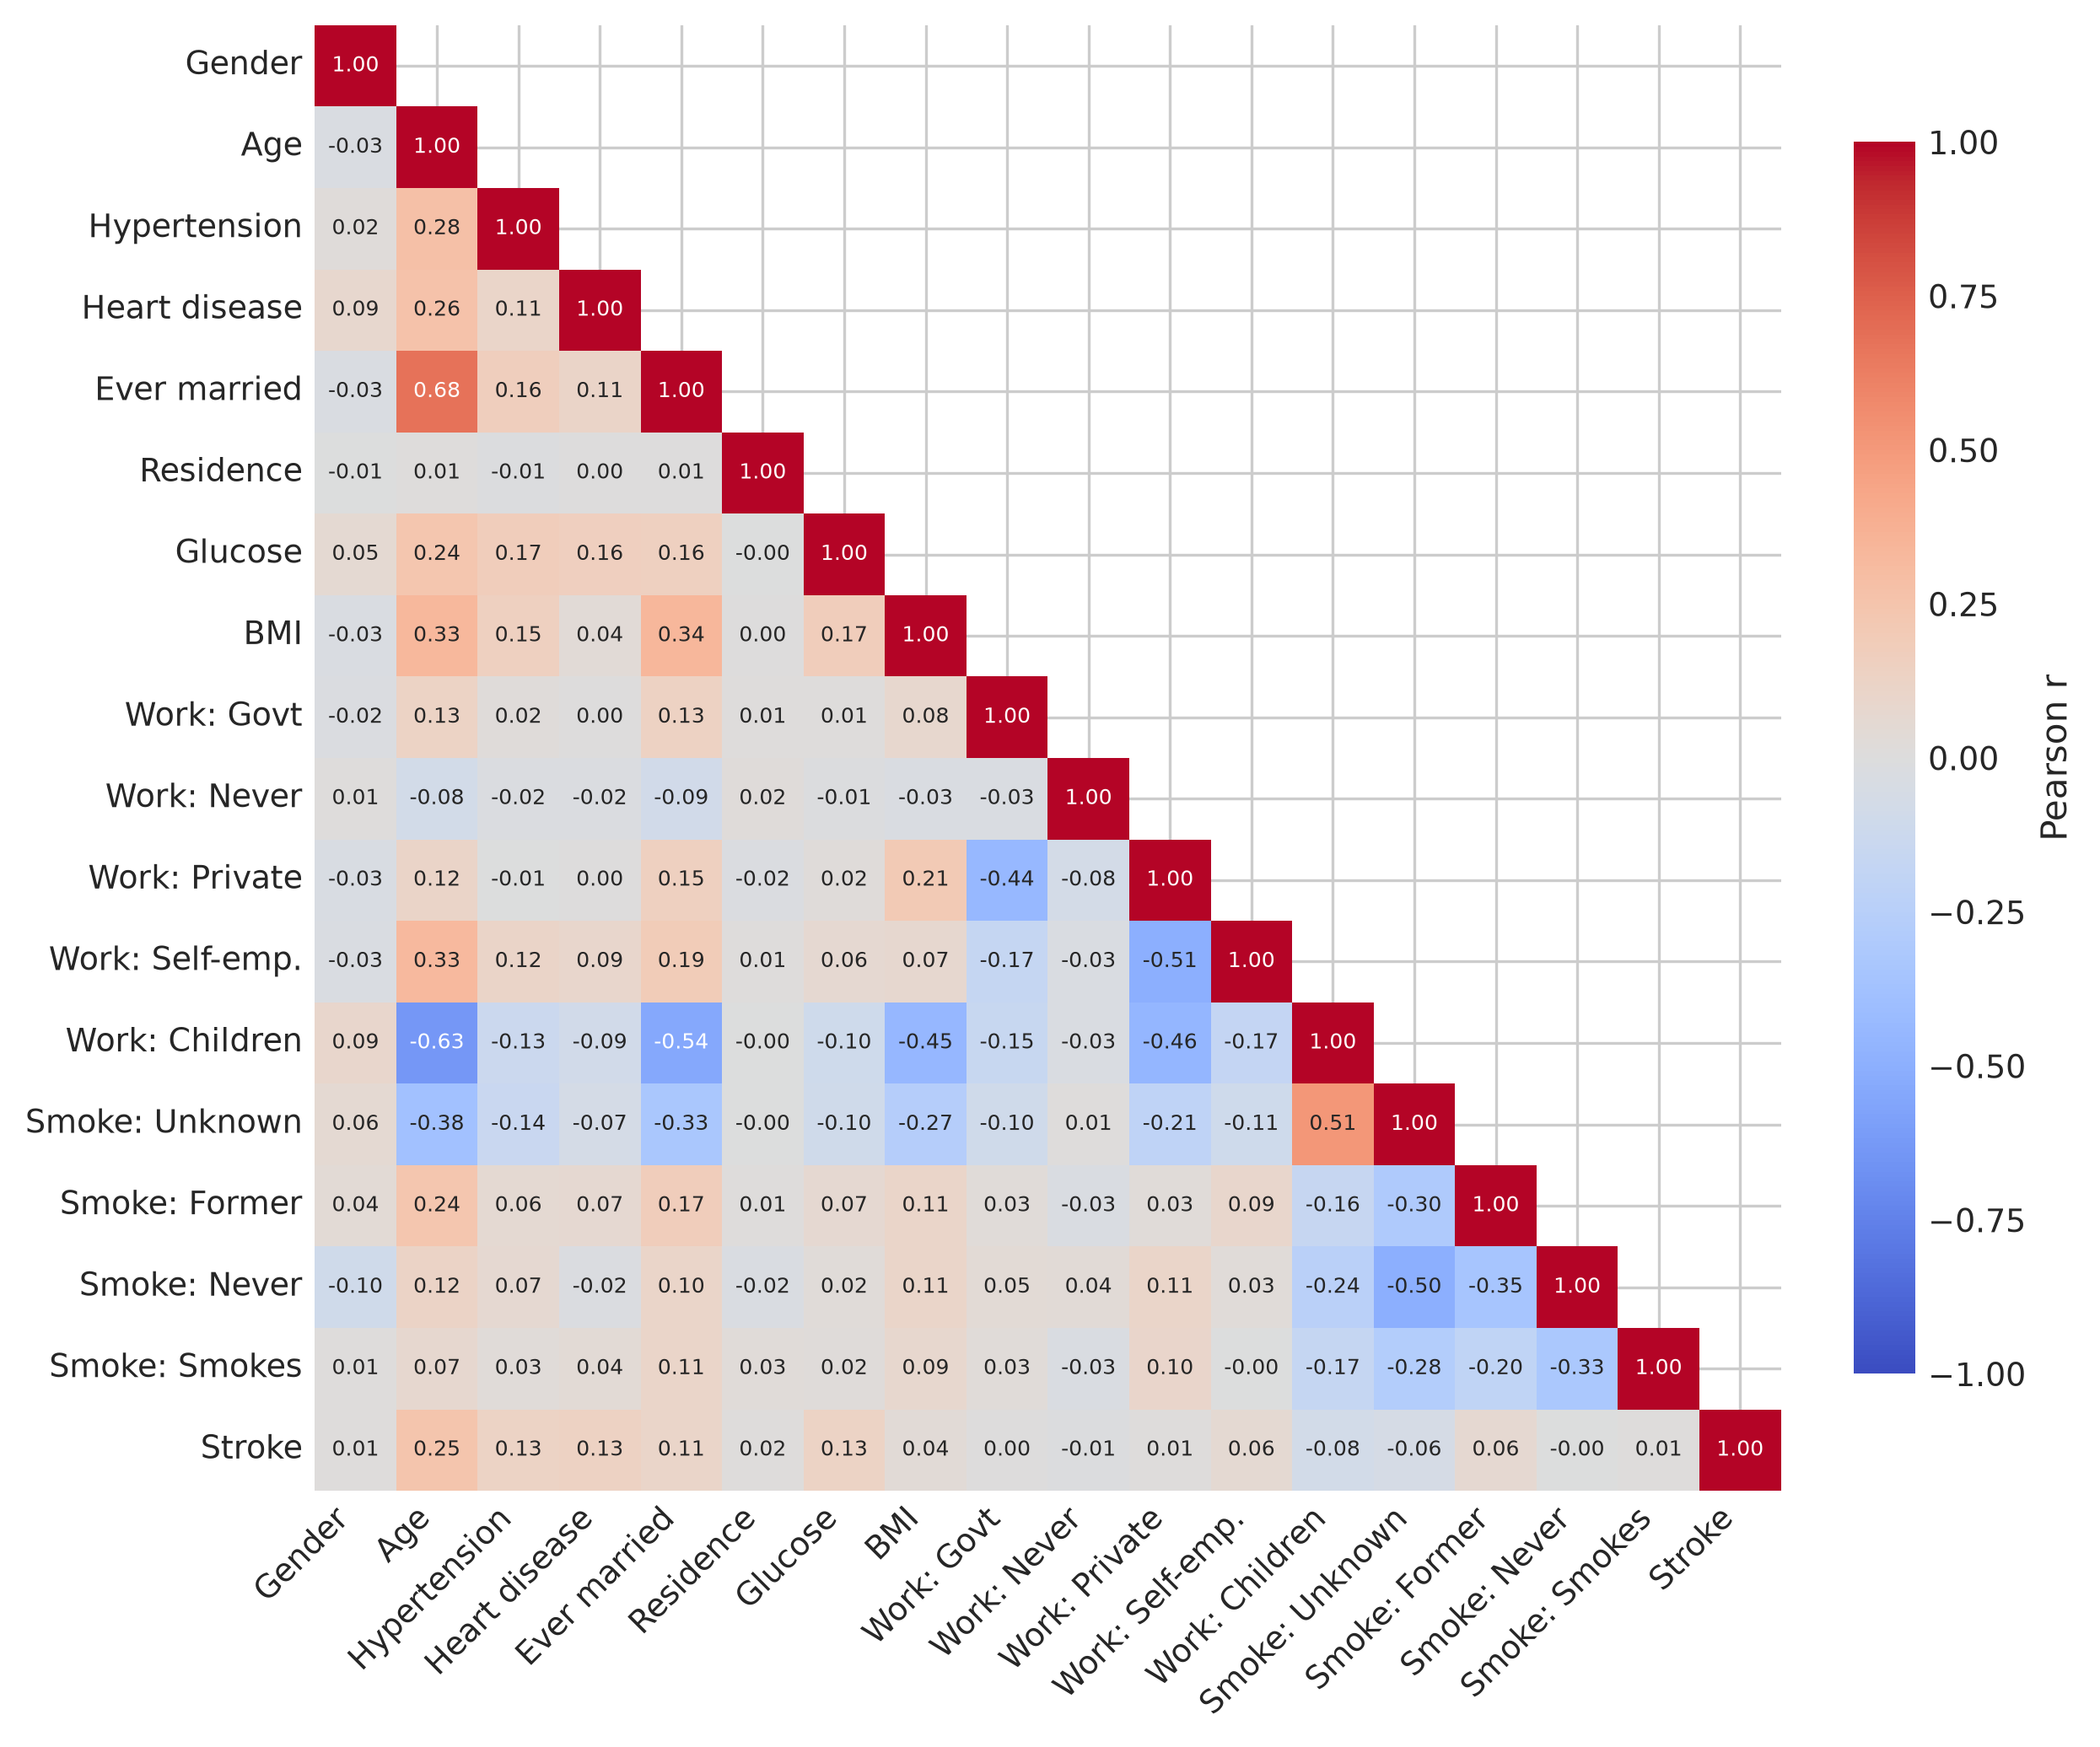

Input A,Input B,Pearson r
age,ever_married,+0.6791
age,work_type_children,-0.6343
ever_married,work_type_children,-0.5447
work_type_children,smoking_status_Unknown,+0.5127
work_type_Private,work_type_Self-employed,-0.5054


Input versus stroke,Pearson r
age,+0.2452
heart_disease,+0.1349
avg_glucose_level,+0.1320
hypertension,+0.1279
ever_married,+0.1083


In [10]:
cov_unscaled = df_clean[numeric_features].cov()
cov_scaled = df_scaled[numeric_features].cov()
fig, axes = plt.subplots(2, 1, figsize=(6.65, 7.6))
short_numeric = ['Age', 'Glucose', 'BMI']
for ax, matrix, title, cmap, fmt in [
    (axes[0], cov_unscaled, 'Sample Covariance — Original Units', 'Blues', '.2f'),
    (axes[1], cov_scaled, 'Sample Covariance — Z-score Features', 'coolwarm', '.4f')]:
    sns.heatmap(matrix, annot=True, fmt=fmt, cmap=cmap, ax=ax, square=True,
                xticklabels=short_numeric, yticklabels=short_numeric, annot_kws={'size': 10})
    ax.set_title(title); ax.tick_params(axis='y', rotation=0)
finish_figure(fig, 'Figure 3: Sample Covariance — Cleaned and Standardized Data',
              f'Top: cleaned measurements. Bottom: standardized features, sample diagonal = {n_samples/(n_samples-1):.4f}.')

full_df = X_encoded.assign(stroke=y)
corr_matrix = full_df.corr()
main_corr = corr_matrix.loc[numeric_features + ['stroke'], numeric_features + ['stroke']]
fig, ax = plt.subplots(figsize=(6.65, 4.6))
sns.heatmap(main_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            square=True, ax=ax, xticklabels=short_numeric+['Stroke'], yticklabels=short_numeric+['Stroke'])
ax.tick_params(axis='y', rotation=0)
finish_figure(fig, 'Figure 4a: Numerical Features and Target — Cleaned Data',
              'Pearson correlation. Stroke is included for descriptive comparison, not PCA fitting.')
short_labels = {
    'gender': 'Gender', 'age': 'Age', 'hypertension': 'Hypertension', 'heart_disease': 'Heart disease',
    'ever_married': 'Ever married', 'Residence_type': 'Residence', 'avg_glucose_level': 'Glucose', 'bmi': 'BMI',
    'work_type_Govt_job': 'Work: Govt', 'work_type_Never_worked': 'Work: Never',
    'work_type_Private': 'Work: Private', 'work_type_Self-employed': 'Work: Self-emp.', 'work_type_children': 'Work: Children',
    'smoking_status_Unknown': 'Smoke: Unknown', 'smoking_status_formerly smoked': 'Smoke: Former',
    'smoking_status_never smoked': 'Smoke: Never', 'smoking_status_smokes': 'Smoke: Smokes', 'stroke': 'Stroke',
}
fig, ax = plt.subplots(figsize=(8.2, 8.2))
sns.heatmap(corr_matrix, mask=np.triu(np.ones_like(corr_matrix, dtype=bool), k=1),
            annot=True, fmt='.2f', annot_kws={'size': 6},
            cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax, square=True,
            xticklabels=[short_labels[c] for c in corr_matrix], yticklabels=[short_labels[c] for c in corr_matrix],
            cbar_kws={'shrink': 0.6, 'label': 'Pearson r'})
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)
finish_figure(fig, 'Figure 4b (Appendix): Full Correlation — Cleaned Encoded Data',
              'All 17 inputs plus stroke. Work/Smoke denote one-hot groups; Govt = Govt_job, Self-emp. = Self-employed, Work: Never = Never_worked. Annotations show r to two decimal places; the upper triangle is omitted.')
input_pairs = []
for i, a in enumerate(feature_names):
    for b in feature_names[i+1:]:
        input_pairs.append((a, b, float(corr_matrix.loc[a, b])))
input_pairs.sort(key=lambda row: abs(row[2]), reverse=True)
top_inputs = pd.DataFrame([[a, b, f'{r:+.4f}'] for a,b,r in input_pairs[:5]], columns=['Input A', 'Input B', 'Pearson r'])
show_table(top_inputs, 'Table 11a. Strongest input-input correlations by absolute r — cleaned encoded data', [42, 42, 16])
target_pairs = sorted([(c, float(corr_matrix.loc[c, 'stroke'])) for c in feature_names], key=lambda row: abs(row[1]), reverse=True)
show_table(pd.DataFrame([[c, f'{r:+.4f}'] for c,r in target_pairs[:5]], columns=['Input versus stroke', 'Pearson r']),
           'Table 11b. Strongest input-target correlations by absolute r — cleaned encoded data', [75, 25])
report_values.update(sample_factor=n_samples/(n_samples-1), strongest_r=input_pairs[0][2],
    structural_r=float(corr_matrix.loc['work_type_Private', 'work_type_Self-employed']))


### 1.9. Covariance and Correlation Analysis

Sample covariance uses $n-1$; Pearson correlation divides covariance by the two sample standard deviations (DM 2.5 [3, pp.7–11] and DM 3 [4, pp.9–16]):

$$s_{xy}=\frac1{n-1}\sum_i(x_i-\bar x)(y_i-\bar y),\qquad
r_{xy}=\frac{s_{xy}}{s_xs_y}.$$

For $Z=X_{\mathrm{scaled}}$, whose columns have variance one with denominator $n$:

$$R=\frac1nZ^TZ,\qquad
C=\frac1{n-1}Z^TZ=\frac{n}{n-1}R\approx 1.00019577\,R.$$

Thus the sample covariance diagonal in Figure 3 is approximately **1.0002**, not exactly one. The small common factor does not change PCA eigenvectors or explained-variance ratios.

The strongest input-input correlation in absolute magnitude is **age ↔ ever_married, $r=+0.6791$** (Table 11a). This is an association with demographic structure, not a causal conclusion.

Negative correlations between dummies of the same variable have a structural component: Private and Self-employed cannot both equal one, and their correlation is $r=-0.5054$. This differs from a relationship between distinct original attributes. The children–Unknown association supports Table 3 but does not establish why smoking information is absent.

Figure 4a presents numerical variables and the target; Figure 4b supplies the full encoded matrix for the report appendix. Pearson $r$ measures linear association only: a small value does not rule out nonlinear dependence, and association does not establish causation.


In [11]:
sample_variances = X_scaled.var(axis=0, ddof=1)
overview = pd.DataFrame([
    ['Records', f'{n_samples:,}'], ['Original input variables', str(input_count)],
    ['Encoded input columns', str(d_encoded)], ['Stroke / No Stroke', f'{int(y.sum()):,} / {int(y.eq(0).sum()):,}'],
    ['Remaining numerical NaN', str(int(np.isnan(X_scaled).sum()))],
    ['Smoking Unknown retained', f'{int(df_clean.smoking_status.eq("Unknown").sum()):,}'],
    ['Feature means', f'[{scaled_means.min():.2e}, {scaled_means.max():.2e}]'],
    ['Variance (ddof=0)', f'[{scaled_variances.min():.4f}, {scaled_variances.max():.4f}]'],
    ['Sample variance (ddof=1)', f'[{sample_variances.min():.4f}, {sample_variances.max():.4f}]'],
    ['External integration', 'Investigated; not performed'],
], columns=['Property', 'Final status'])
show_table(overview, 'Table 12. Final preprocessing state — cleaned / standardized data', [50, 50])
report_values.update(clean_yes=int(y.sum()), clean_no=int(y.eq(0).sum()), clean_ratio=float(y.eq(0).sum()/y.sum()))


Property,Final status
Records,"5,109"
Original input variables,10
Encoded input columns,17
Stroke / No Stroke,"249 / 4,860"
Remaining numerical NaN,0
Smoking Unknown retained,"1,544"
Feature means,"[-1.61e-16, 1.22e-16]"
Variance (ddof=0),"[1.0000, 1.0000]"
Sample variance (ddof=1),"[1.0002, 1.0002]"
External integration,Investigated; not performed


### 1.10. Summary of Part 1

Preprocessing produces a complete numerical matrix with **5,109 records and 17 encoded inputs** (Table 12). Removing the identifier avoids an arbitrary coordinate, encoding avoids artificial nominal ordering, and scaling reduces disparities caused by measurement units.

Trade-offs remain: 1 recorded gender category observation is excluded, median imputation concentrates BMI at **28.10**, and capping alters 13 observations. One-hot expansion gives different numbers of standardized columns to different original variables.

BMI missingness is greater in stroke records (16.06% versus 3.31%), and smoking information remains unavailable for 30.22% of records. External integration is investigated but not performed. PCA findings are conditional on these preprocessing choices and do not establish causal or prospective clinical conclusions.


In [12]:
pca_full = PCA(svd_solver='auto', random_state=RANDOM_STATE)
pca_full.fit(X_scaled)
Y_all = pca_full.transform(X_scaled)
# sklearn versions differ: 1.9.1 exposes the fitted selection as _fit_svd_solver.
actual_solver = getattr(pca_full, 'svd_solver_', None)
solver_attribute = 'svd_solver_'
if actual_solver is None:
    actual_solver = getattr(pca_full, '_fit_svd_solver', 'not exposed by this version')
    solver_attribute = '_fit_svd_solver'
C_manual = X_scaled.T @ X_scaled / (n_samples - 1)
eigenvalues_manual, eigenvectors_manual = np.linalg.eigh(C_manual)
order = np.argsort(eigenvalues_manual)[::-1]
eigenvalues_manual, eigenvectors_manual = eigenvalues_manual[order], eigenvectors_manual[:, order]
diff_eigenvalues = float(np.max(np.abs(pca_full.explained_variance_ - eigenvalues_manual)))
orthonormality_error = float(np.max(np.abs(eigenvectors_manual.T @ eigenvectors_manual - np.eye(d_encoded))))
covariance_rank = int(np.linalg.matrix_rank(C_manual))
covariance_trace = float(np.trace(C_manual))
print(f'Configured solver: {pca_full.svd_solver}; actual fitted solver: {actual_solver} ({solver_attribute}).')
print(f'n = {n_samples}; d = {d_encoded}; rank(C) = {covariance_rank}; trace(C) = {covariance_trace:.8f}')
print(f'Max eigenvalue discrepancy: {diff_eigenvalues:.4e}')
print(f'Max orthonormality discrepancy: {orthonormality_error:.4e}')
print(f'Covariance eigenvalues non-negative within 1e-12: {bool((eigenvalues_manual >= -1e-12).all())}')
assert diff_eigenvalues < 1e-12 and orthonormality_error < 1e-12
report_values.update(actual_solver=actual_solver, eig_error=diff_eigenvalues, orth_error=orthonormality_error,
    rank=covariance_rank, trace=covariance_trace,
    pc7_rare=float(pca_full.components_[6, rare_index]))


Configured solver: auto; actual fitted solver: covariance_eigh (_fit_svd_solver).
n = 5109; d = 17; rank(C) = 15; trace(C) = 17.00332811
Max eigenvalue discrepancy: 1.1794e-15
Max orthonormality discrepancy: 2.6645e-15
Covariance eigenvalues non-negative within 1e-12: True


## Part 2 — Principal Component Analysis
### 2.1. PCA Computation

Following DM 3 [4, p.27], the encoded data are centered, their covariance matrix is formed, and eigenvectors are ordered by decreasing eigenvalue. Scaling has already been applied in Section 1.7:

$$C=\frac1{n-1}Z^TZ,\qquad C\mathbf v_j=\lambda_j\mathbf v_j,\qquad
V^TV=I,\qquad \lambda_1\ge\cdots\ge\lambda_d\ge0,\qquad Y_p=ZV_p.$$

Here $V_p$ stores the selected unit eigenvectors as columns; $Y_p$ stores patient scores by row. `svd_solver='auto'` selects **`covariance_eigh`** in this execution. Eigenvalue discrepancy is **1.1794e-15** and orthonormality discrepancy **2.6645e-15**, below $10^{-14}$ in the recorded execution. These checks establish floating-point consistency, not an independent full-SVD benchmark or exact zero numerical error.

SVD provides another route (DM 3 [4, pp.34–35]):

$$Z=USV^T,\qquad \lambda_j=\frac{s_j^2}{n-1}.$$

The diagonal entries $s_j$ of $S$ are singular values. SVD can avoid explicitly forming the $d\times d$ covariance matrix when the feature dimension is large.


PC,Eigenvalue,EVR (%),Cumulative (%)
PC1,3.3874,19.92,19.92
PC2,1.7396,10.23,30.15
PC3,1.4734,8.67,38.82
PC4,1.2454,7.32,46.14
PC5,1.1653,6.85,53.00
PC6,1.1243,6.61,59.61
PC7,1.0344,6.08,65.69
PC8,0.9801,5.76,71.46
PC9,0.9360,5.51,76.96
PC10,0.8920,5.25,82.21



Selection criteria:
Primary: at least 80%: p=10; retained=82.21%; reduction=41.2%.
Alternative: at least 90%: p=12; retained=92.08%; reduction=29.4%.
Kaiser comparison: p=7; retained=65.69%; reduction=58.8%.
Kaiser threshold for this sample-covariance convention: 1.00019577.


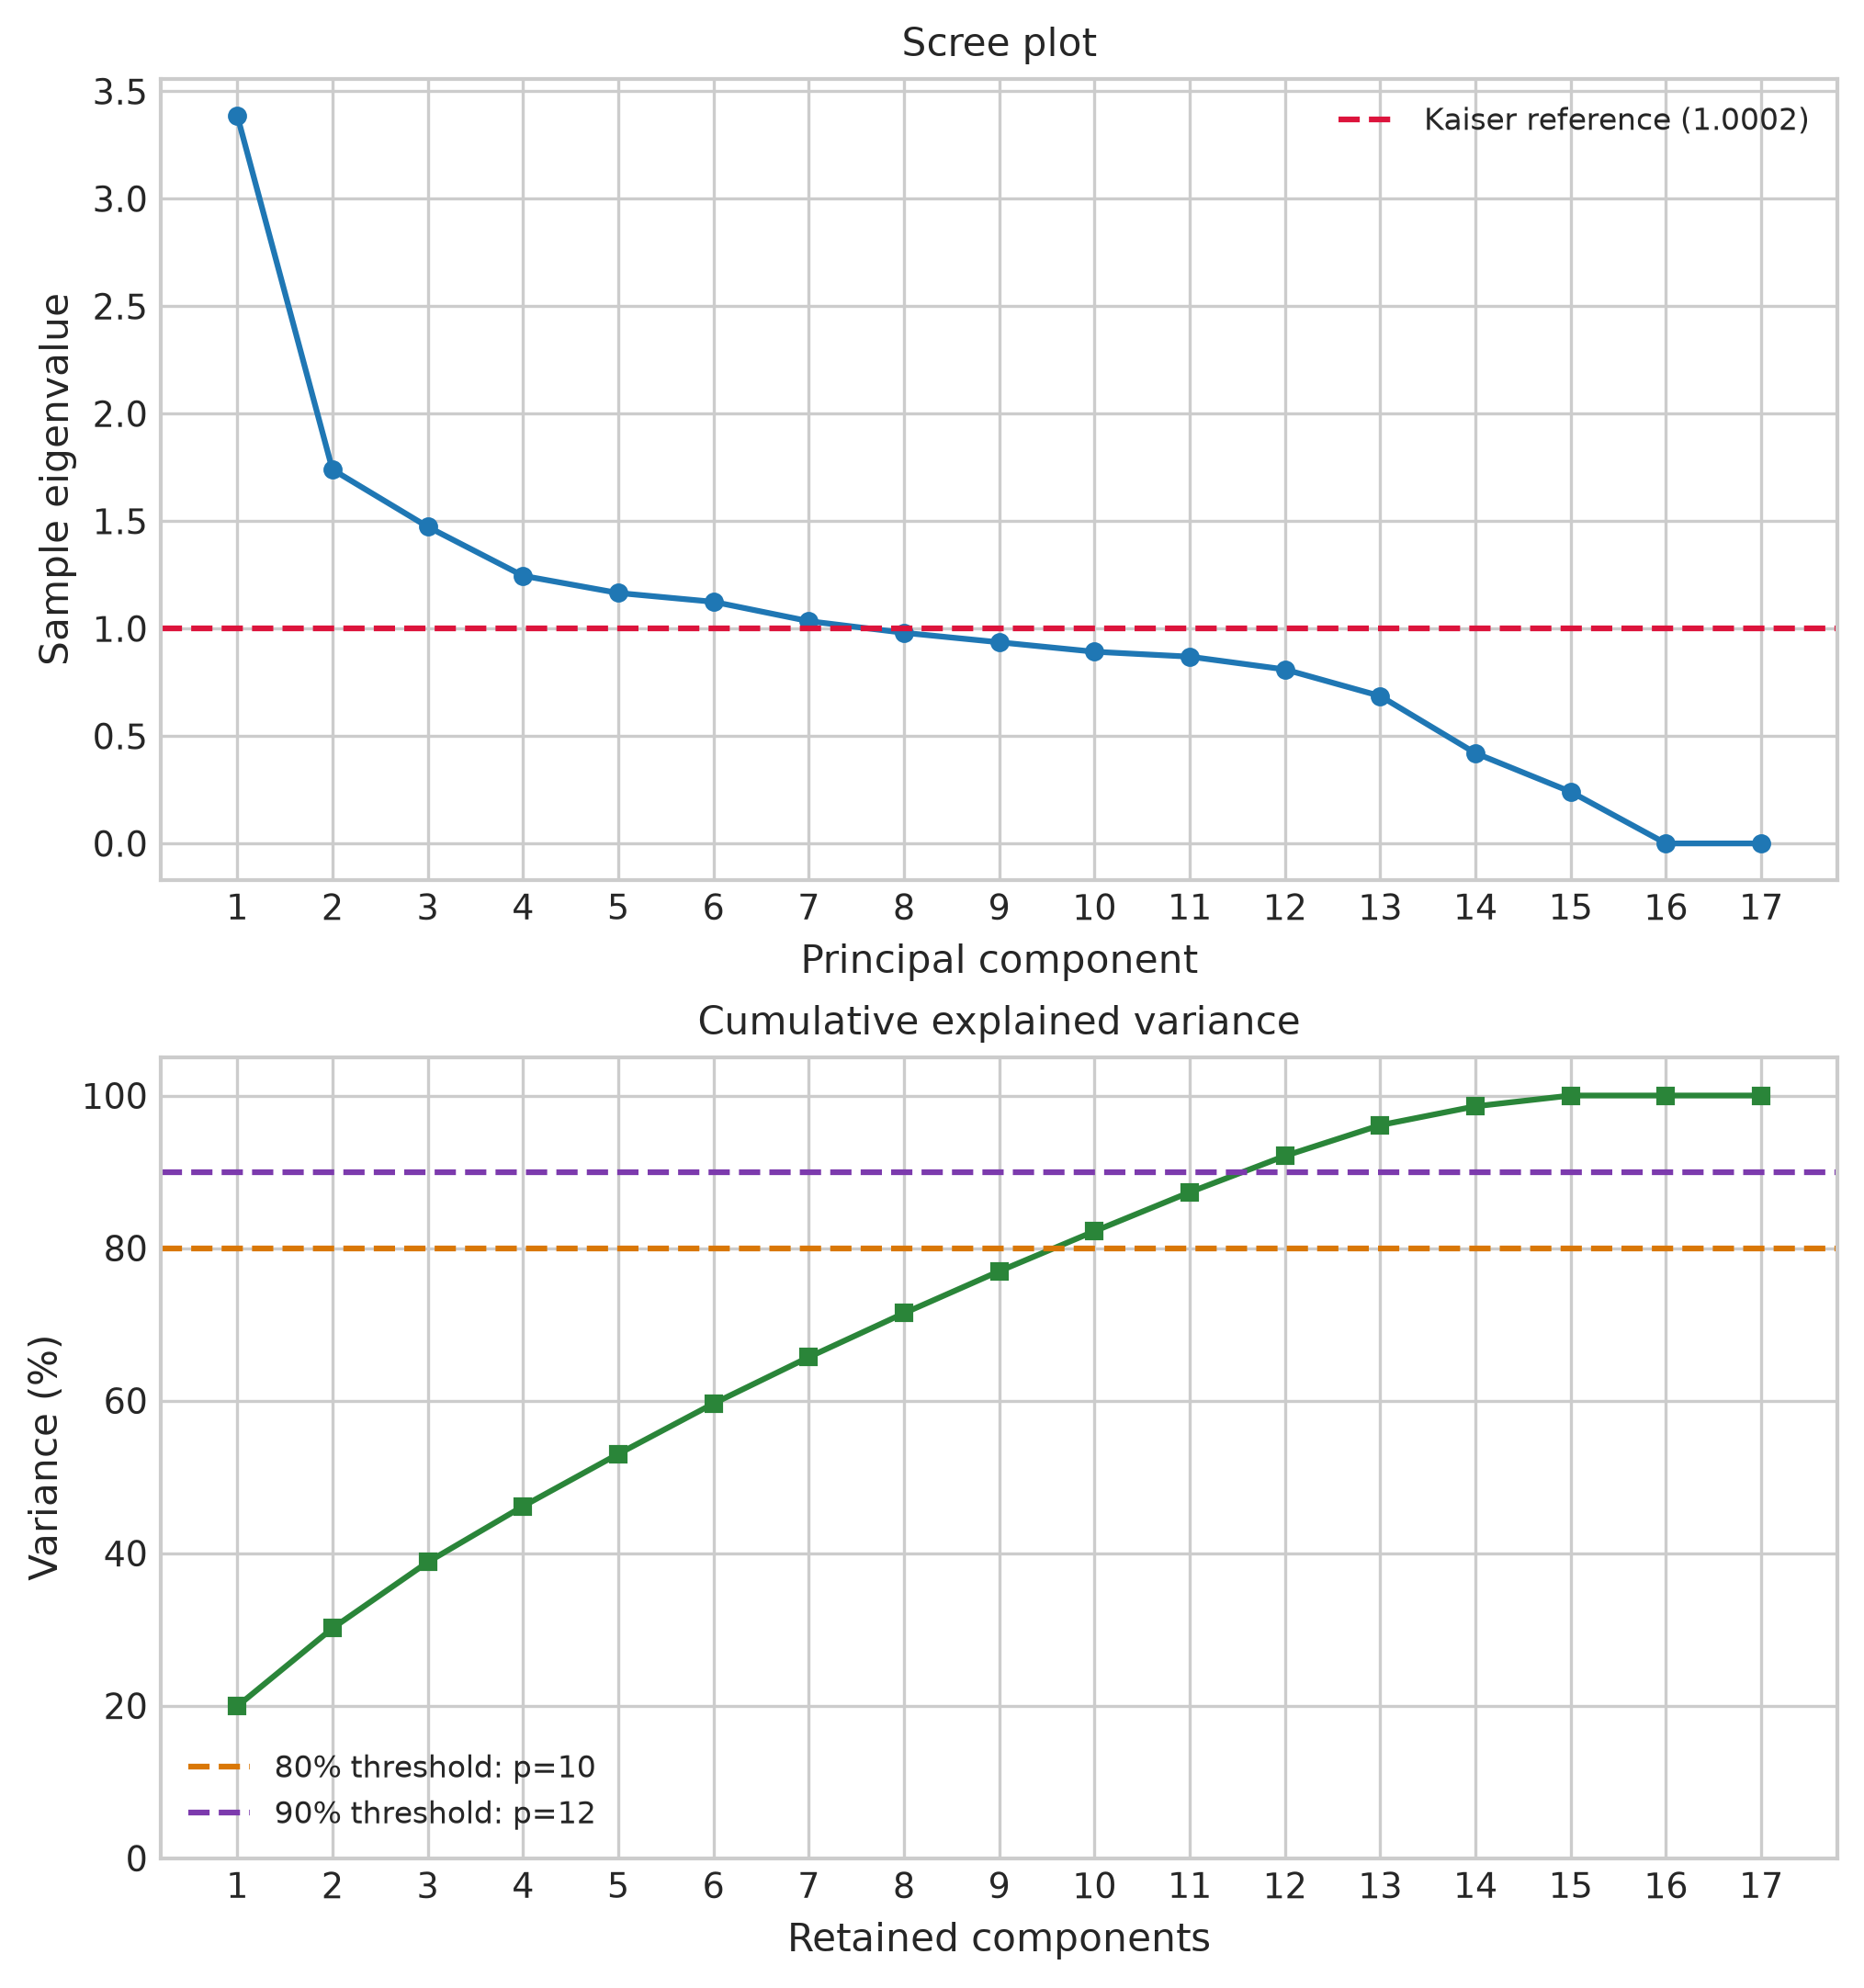

In [13]:
eigenvalues = pca_full.explained_variance_.copy()
evr_fraction = pca_full.explained_variance_ratio_.copy()
evr = 100*evr_fraction
cevr = np.cumsum(evr)
p_80 = int(np.searchsorted(cevr, 80) + 1)
p_90 = int(np.searchsorted(cevr, 90) + 1)
kaiser_threshold = n_samples/(n_samples-1)
kaiser_p = int((eigenvalues > kaiser_threshold).sum())
variance_table = pd.DataFrame({
    'PC': [f'PC{i+1}' for i in range(d_encoded)],
    'Eigenvalue': [f'{x:.4f}' for x in eigenvalues],
    'EVR (%)': [f'{x:.2f}' for x in evr], 'Cumulative (%)': [f'{x:.2f}' for x in cevr]})
show_table(variance_table, 'Table 13. Explained variance — standardized inputs', [16, 28, 26, 30],
           'Ratios use unrounded eigenvalues. Near-zero entries are displayed to four decimal places.')
print('\nSelection criteria:')
for title, p in [('Primary: at least 80%', p_80), ('Alternative: at least 90%', p_90), ('Kaiser comparison', kaiser_p)]:
    print(f'{title}: p={p}; retained={cevr[p-1]:.2f}%; reduction={100*(1-p/d_encoded):.1f}%.')
print(f'Kaiser threshold for this sample-covariance convention: {kaiser_threshold:.8f}.')
fig, axes = plt.subplots(2, 1, figsize=(6.65, 7.1))
indices = np.arange(1, d_encoded+1)
axes[0].plot(indices, eigenvalues, 'o-', markersize=4)
axes[0].axhline(kaiser_threshold, color='crimson', ls='--', label=f'Kaiser reference ({kaiser_threshold:.4f})')
axes[0].set(title='Scree plot', xlabel='Principal component', ylabel='Sample eigenvalue', xticks=indices)
axes[0].legend()
axes[1].plot(indices, cevr, 's-', color='#2a8539', markersize=4)
for level, color, p in [(80, '#d97706', p_80), (90, '#7c3aad', p_90)]:
    axes[1].axhline(level, color=color, ls='--', label=f'{level}% threshold: p={p}')
axes[1].set(title='Cumulative explained variance', xlabel='Retained components', ylabel='Variance (%)', xticks=indices, ylim=(0,105))
axes[1].legend()
finish_figure(fig, 'Figure 5: PCA Variance and Selection — Standardized Data',
              'The primary choice is the smallest p reaching 80%; the 90% and Kaiser rules are comparisons.')
report_values.update(p_primary=p_80, p_alternative=p_90, p_kaiser=kaiser_p,
    primary_var=float(cevr[p_80-1]), alternative_var=float(cevr[p_90-1]), kaiser_var=float(cevr[kaiser_p-1]),
    primary_reduction=100*(1-p_80/d_encoded), alternative_reduction=100*(1-p_90/d_encoded),
    pc1_var=float(evr[0]), pc2_var=float(evr[1]), first2_var=float(evr[:2].sum()))


### 2.2. Explained Variance and Component Selection

Under the sample-covariance convention used here:

$$\operatorname{tr}(C)=\sum_{j=1}^d\lambda_j
=d\frac{n}{n-1}\approx 17.0033.$$

$$\mathrm{EVR}_j=\frac{\lambda_j}{\sum_{k=1}^d\lambda_k},\qquad
\mathrm{CEVR}_p=\frac{\sum_{j=1}^p\lambda_j}{\sum_{k=1}^d\lambda_k}.$$

Table 13 reports percentages, whereas these equations use ratios in $[0,1]$. The scree plot declines gradually without a sharp single elbow. Following DM 3's 80–90% guidance [4, p.29], the primary selection is **$p=10$**, the smallest number exceeding 80%: it retains **82.21%** and reduces columns by **41.2%**. The higher-retention alternative is **$p=12$**, the smallest number reaching 90%, retaining **92.08%** with **29.4%** reduction.

Kaiser's rule is a comparison: **$p=7$ retains 65.69%**. The reference of one concerns standardized-variable variance in correlation-based PCA, not an eigenvalue assigned to each original feature. With this sample covariance, the equivalent threshold is $\lambda_j>n/(n-1)\approx 1.0002$.

Full one-hot groups each sum to one. After centering and scaling, each group gives a linear constraint (equivalently $\sum_k\sigma_k z_k=0$ within that group). The resulting **$\operatorname{rank}(C)=15$** produces two theoretically zero-variance directions, PC16 and PC17, rather than idiosyncratic noise. Near-zero numerical eigenvalues are interpreted within tolerance.

High variance describes dominant variation in this chosen representation; it does not guarantee predictive importance for stroke. Low but non-zero variance does not imply absence of target association. PCA is feature extraction, creating new combinations, rather than selecting original variables (DM 2.5 [3, p.4]).


p,Reduction (%),Retained (%),Discarded (%)
1,94.1,19.92,80.08
2,88.2,30.15,69.85
3,82.4,38.82,61.18
5,70.6,53.00,47.00
7,58.8,65.69,34.31
10,41.2,82.21,17.79
12,29.4,92.08,7.92
14,17.6,98.59,1.41
15,11.8,100.00,0.00
17,0.0,100.00,0.00


p,Empirical MSE,Corrected MSE
1,0.80078,0.80078
2,0.69847,0.69847
3,0.61182,0.61182
5,0.47003,0.47003
7,0.34308,0.34308
10,0.17793,0.17793
12,0.07920,0.07920
14,0.01414,0.01414
15,0.00000,0.00000
17,0.00000,0.00000


Max empirical/theoretical MSE discrepancy: 2.2204e-16
Max MSE versus (1 - CEVR) discrepancy: 3.3307e-16


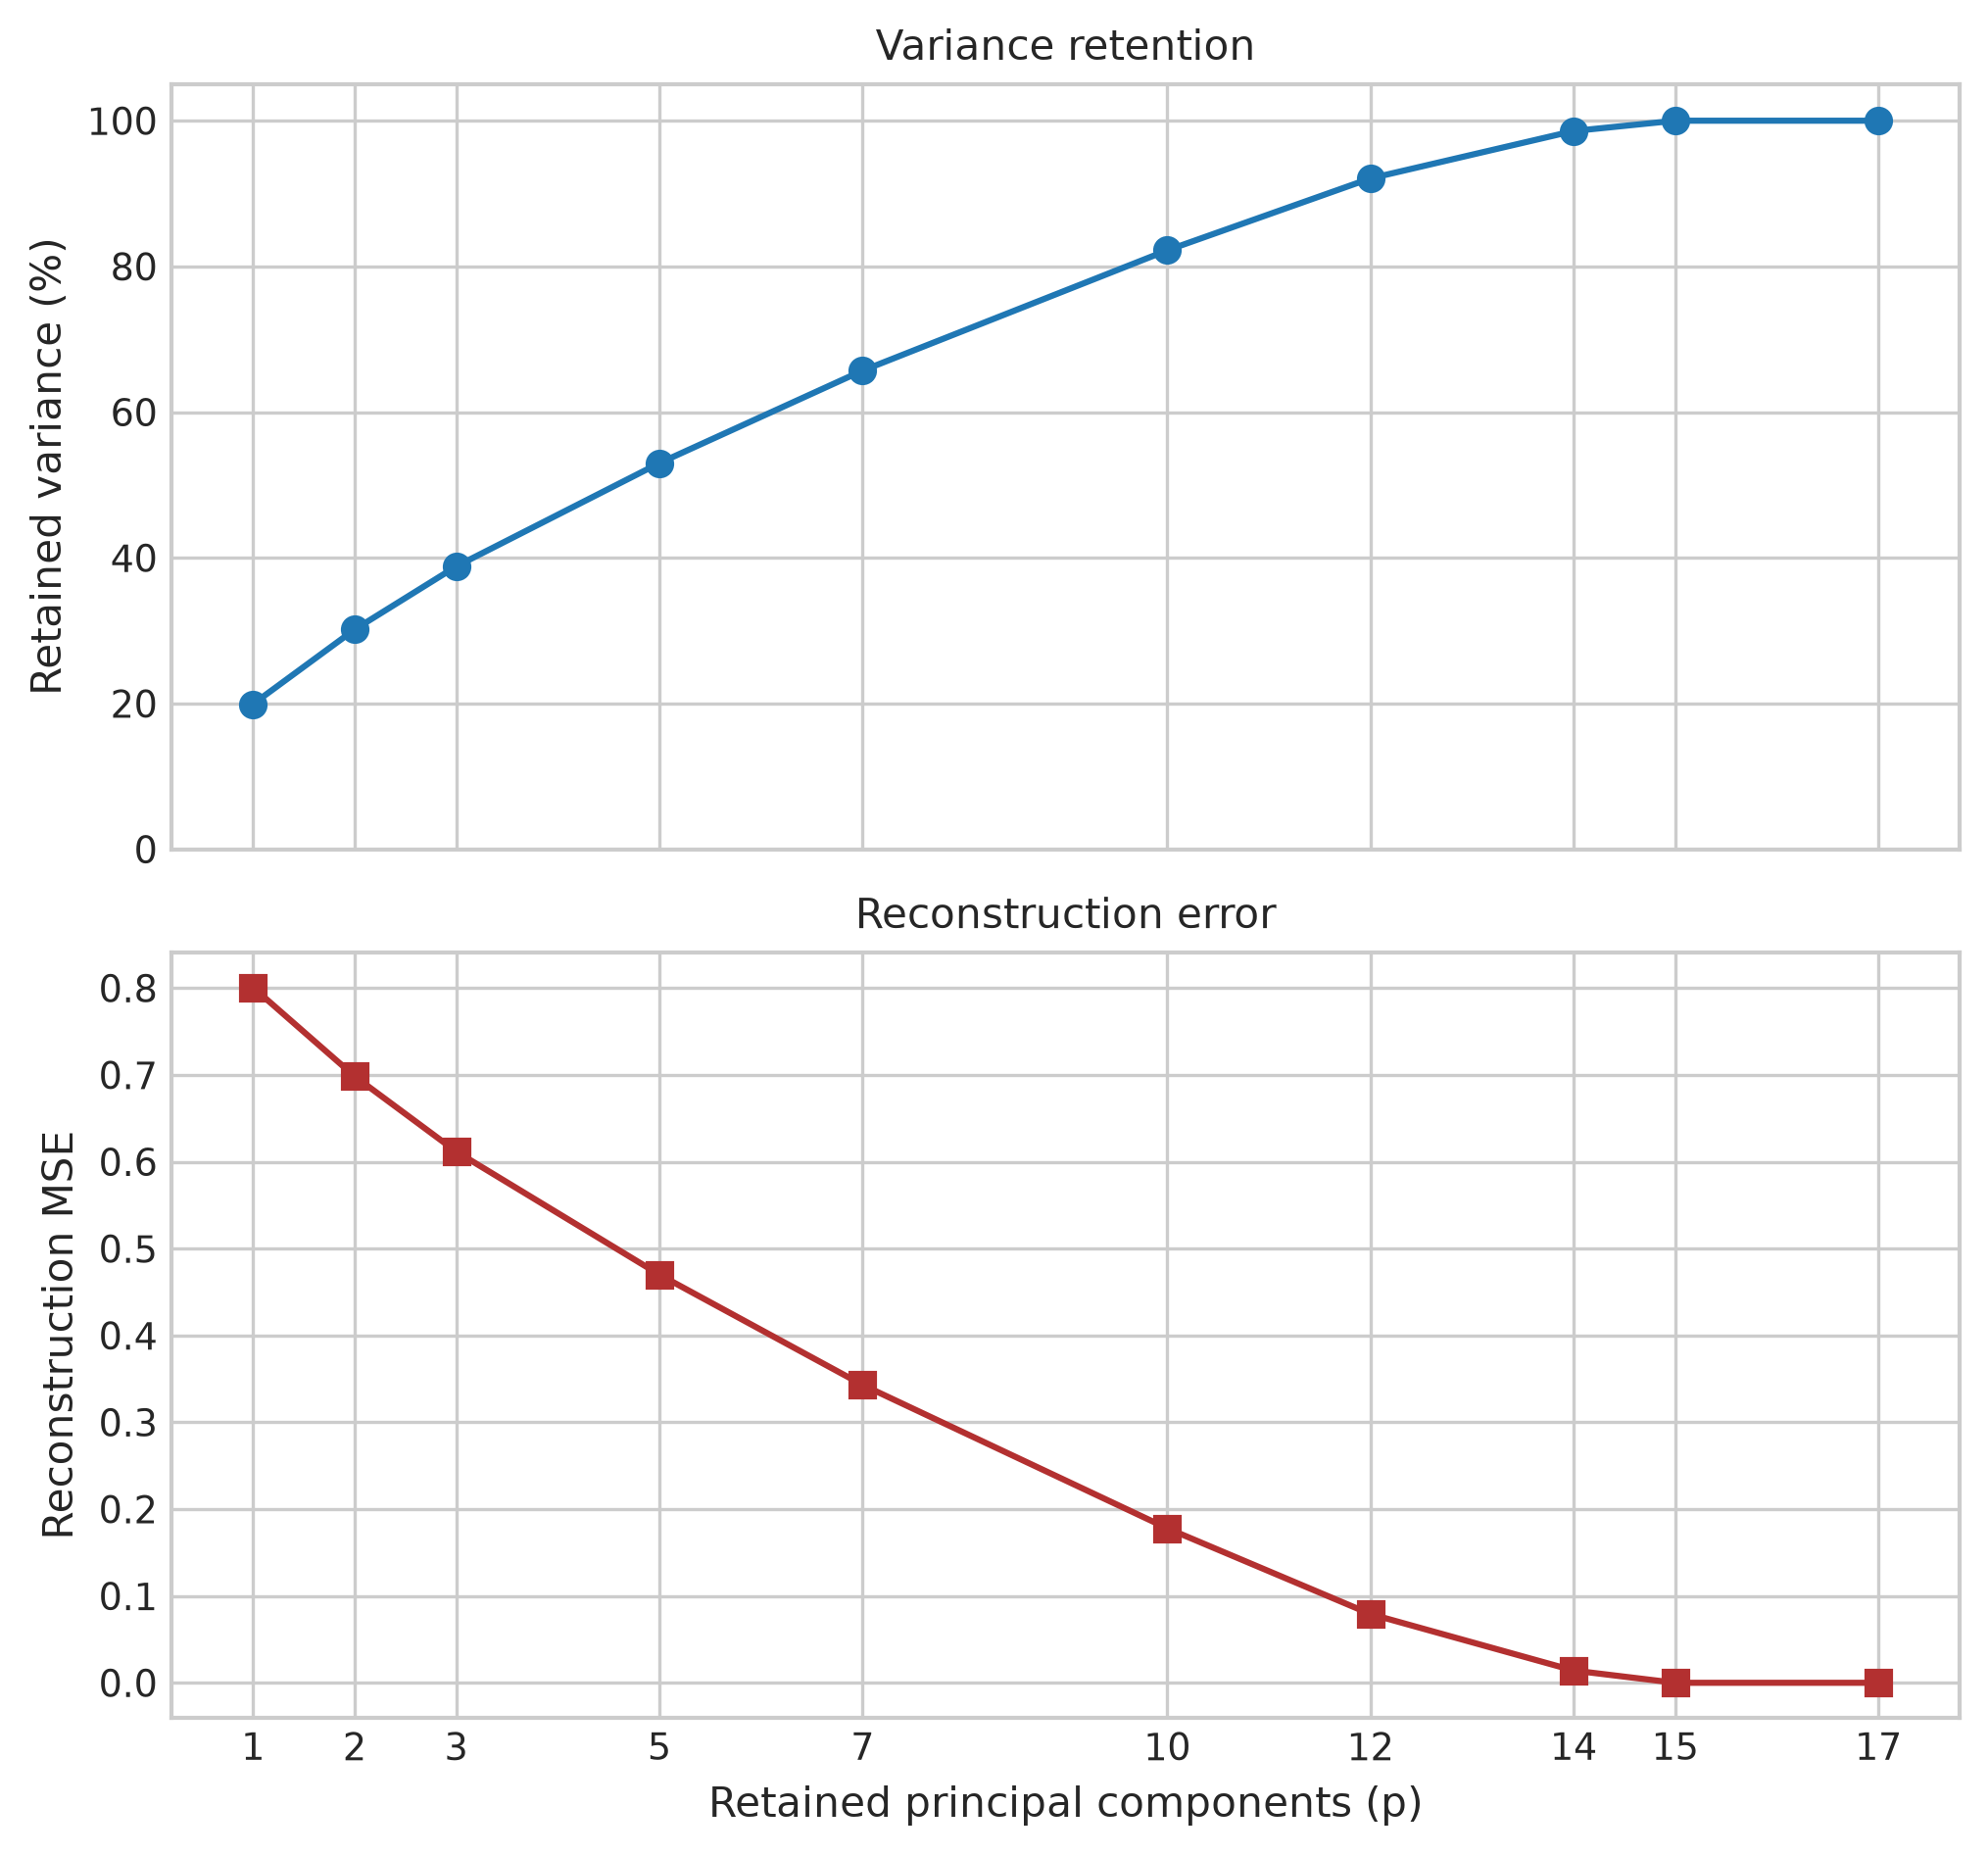

In [14]:
p_choices = [1, 2, 3, 5, 7, 10, 12, 14, 15, 17]
recon_records = []
for p in p_choices:
    # Every projection uses the same fitted pca_full basis and center.
    Y_p = Y_all[:, :p]
    X_hat = Y_p @ pca_full.components_[:p, :] + pca_full.mean_
    empirical_mse = float(np.mean((X_scaled-X_hat)**2))
    theoretical_mse = ((n_samples-1.0)/(n_samples*X_scaled.shape[1])) * np.sum(eigenvalues[p:])
    retained = float(evr_fraction[:p].sum())
    recon_records.append([p, 100*(1-p/d_encoded), 100*retained, 100*(1-retained), empirical_mse, float(theoretical_mse)])
df_recon_results = pd.DataFrame(recon_records, columns=['p', 'Reduction (%)', 'Retained (%)', 'Discarded (%)', 'Empirical MSE', 'Corrected MSE'])
retention = df_recon_results.iloc[:, :4].copy()
retention['Reduction (%)'] = retention['Reduction (%)'].map('{:.1f}'.format)
for c in ['Retained (%)', 'Discarded (%)']: retention[c] = retention[c].map(lambda value: f'{max(0.,value):.2f}')
show_table(retention, 'Table 14a. Dimensionality and retained variance — standardized data', [10, 30, 30, 30])
errors = df_recon_results[['p', 'Empirical MSE', 'Corrected MSE']].copy()
for c in ['Empirical MSE', 'Corrected MSE']: errors[c] = errors[c].map('{:.5f}'.format)
show_table(errors, 'Table 14b. Reconstruction error — standardized data', [12, 44, 44],
           'Values displayed as 0.00000 are interpreted within floating-point precision.')
max_mse_gap = float(np.max(np.abs(df_recon_results['Empirical MSE']-df_recon_results['Corrected MSE'])))
coupling_gap = float(np.max(np.abs(df_recon_results['Empirical MSE']-(1-df_recon_results['Retained (%)']/100))))
assert max_mse_gap < 1e-12 and coupling_gap < 1e-12
print(f'Max empirical/theoretical MSE discrepancy: {max_mse_gap:.4e}')
print(f'Max MSE versus (1 - CEVR) discrepancy: {coupling_gap:.4e}')
fig, axes = plt.subplots(2, 1, figsize=(6.65, 6.2), sharex=True)
axes[0].plot(p_choices, df_recon_results['Retained (%)'], 'o-', color='#1f77b4')
axes[0].set(ylabel='Retained variance (%)', ylim=(0,105), title='Variance retention')
axes[1].plot(p_choices, df_recon_results['Empirical MSE'], 's-', color='#b33030')
axes[1].set(xlabel='Retained principal components (p)', ylabel='Reconstruction MSE', title='Reconstruction error', xticks=p_choices)
finish_figure(fig, 'Figure 6: Reduction and Reconstruction — Standardized Data',
              'Panels share p but have separate vertical axes. Retained variance and MSE are mathematically coupled.')
report_values.update(max_mse_gap=max_mse_gap, coupling_gap=coupling_gap,
    primary_mse=float(df_recon_results.set_index('p').loc[p_80, 'Empirical MSE']))


### 2.3. Dimensionality Reduction and Reconstruction

All reconstructions use the same fitted PCA basis. In centered standardized coordinates:

$$Y_p=ZV_p,\qquad \hat Z=Y_pV_p^T,$$

$$\mathrm{MSE}(p)=\frac1{nd}\lVert Z-\hat Z\rVert_F^2
=\frac{n-1}{nd}\sum_{j=p+1}^d\lambda_j
=1-\mathrm{CEVR}_p.$$

CEVR is a ratio in $[0,1]$. The implementation includes the fitted mean when reconstructing, accounting for any residual floating-point centering error. The last equality follows because the population variance of each standardized column is one; it is not a general identity for unscaled data.

For **$p=10$**, variance retention is **82.21%**, dimension reduction **41.2%**, and MSE **0.17793**. Empirical and corrected theoretical errors agree within floating-point tolerance across the tested values (maximum discrepancy **2.2204e-16**).

Retained variance and MSE are mathematically coupled, not independent evidence of analytical or predictive quality. At $p=15$, reconstruction recovers the **preprocessed standardized matrix** to numerical precision. It does not restore missing BMI, uncapped values, the excluded record, or stroke-prediction accuracy.


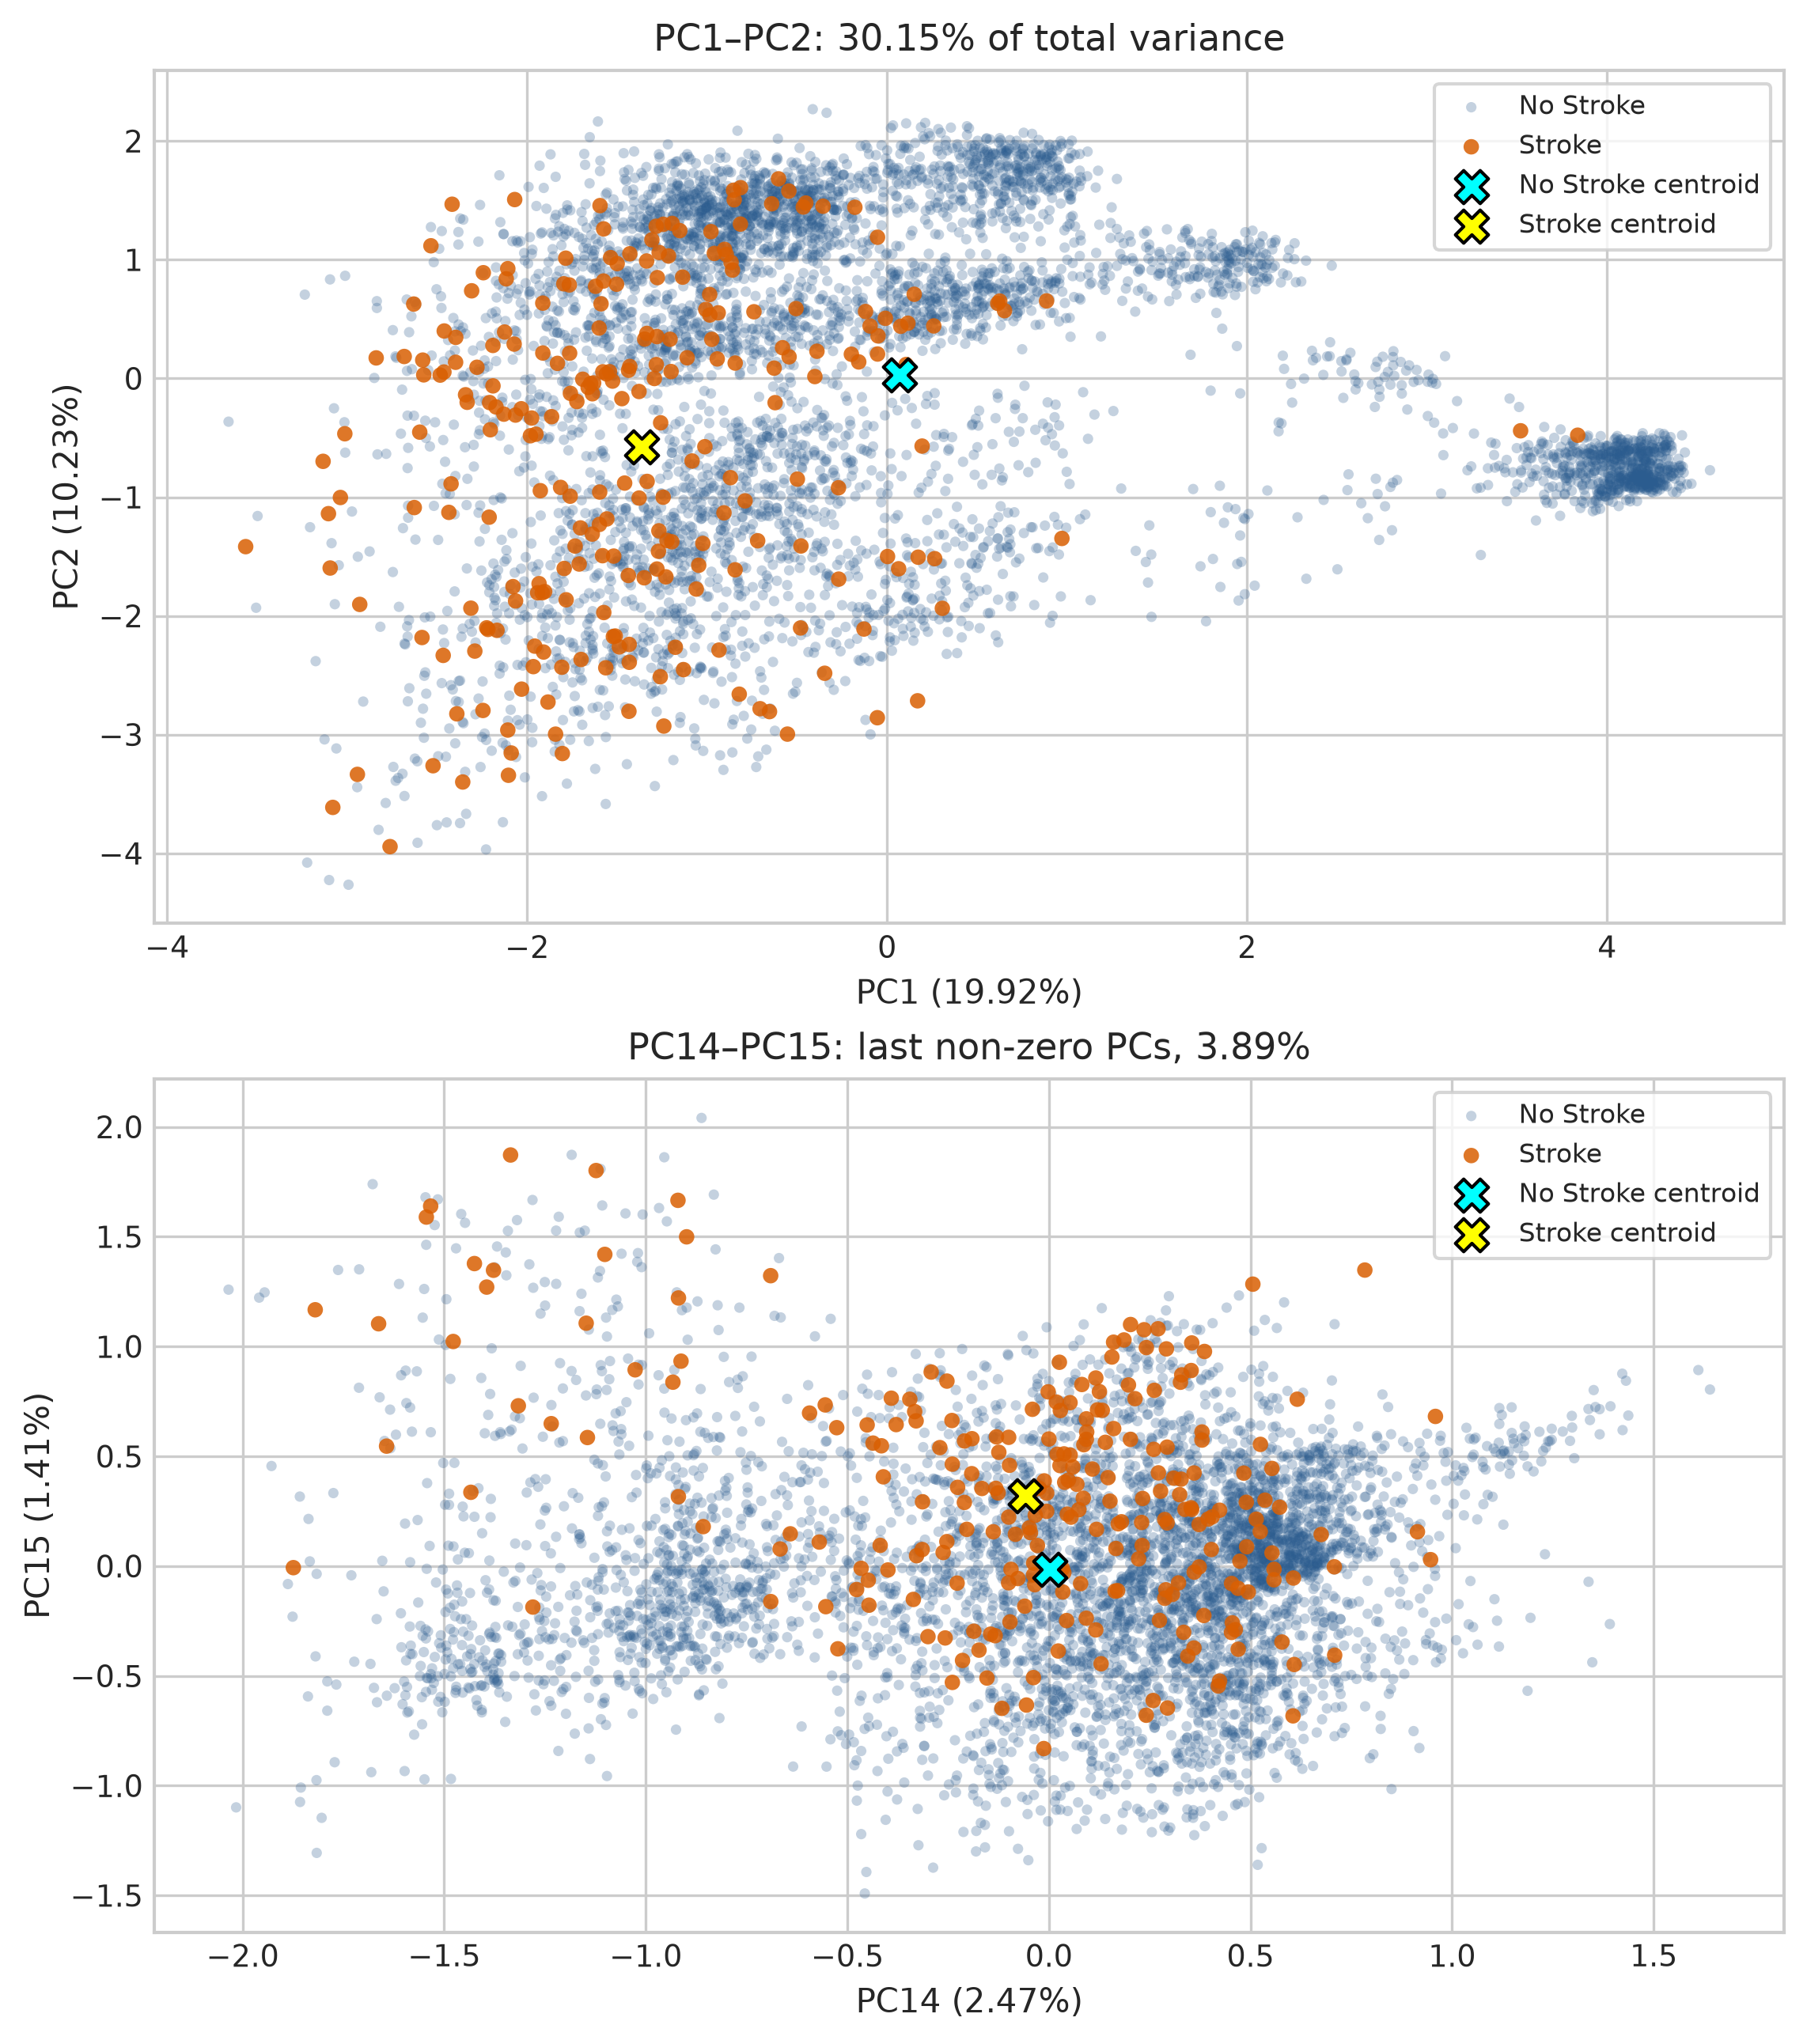

No Stroke centroid (PC1, PC2): [0.0698, 0.0295]
Stroke centroid (PC1, PC2): [-1.3625, -0.5756]
Centroid distance: 1.5549
PC14 + PC15 EVR (sum before rounding): 3.885262974083% -> 3.89%
Pearson r(PC15, stroke): 0.147317


In [15]:
Y_all = pca_full.transform(X_scaled)
Y_first2 = Y_all[:, :2]
Y_last2 = Y_all[:, 13:15]
centroid_0_first = Y_first2[y.eq(0)].mean(axis=0)
centroid_1_first = Y_first2[y.eq(1)].mean(axis=0)
centroid_distance = float(np.linalg.norm(centroid_1_first-centroid_0_first))
last2_var = float(evr[13:15].sum())
pc15_target_r = float(np.corrcoef(Y_all[:,14], y)[0,1])
fig, axes = plt.subplots(2, 1, figsize=(7.5, 8.5))
for ax, scores, first_index, title in [
    (axes[0], Y_first2, 0, f'PC1–PC2: {evr[:2].sum():.2f}% of total variance'),
    (axes[1], Y_last2, 13, f'PC14–PC15: last non-zero PCs, {last2_var:.2f}%')]:
    for label, color, size, alpha in [(0, '#2b5c8f', 10, 0.28), (1, '#d95f02', 22, 0.85)]:
        selected = y.eq(label).to_numpy()
        ax.scatter(scores[selected,0], scores[selected,1], c=color, s=size, alpha=alpha,
                   label='No Stroke' if label==0 else 'Stroke', edgecolors='none')
    for label, color in [(0, 'cyan'), (1, 'yellow')]:
        center = scores[y.eq(label)].mean(axis=0)
        ax.scatter(*center, c=color, s=100, marker='X', edgecolors='black', linewidth=1,
                   label='No Stroke centroid' if label==0 else 'Stroke centroid')
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(f'PC{first_index+1} ({evr[first_index]:.2f}%)')
    ax.set_ylabel(f'PC{first_index+2} ({evr[first_index+1]:.2f}%)')
    ax.legend(loc='upper right', fontsize=8, frameon=True)
finish_figure(fig, 'Figure 7: Label-Colored PCA Projections — Standardized Data',
              'Both panels use pca_full. Panel scales differ. Centroid shifts and visual overlap are descriptive, not classifier validation.')
print(f'No Stroke centroid (PC1, PC2): [{centroid_0_first[0]:.4f}, {centroid_0_first[1]:.4f}]')
print(f'Stroke centroid (PC1, PC2): [{centroid_1_first[0]:.4f}, {centroid_1_first[1]:.4f}]')
print(f'Centroid distance: {centroid_distance:.4f}')
print(f'PC14 + PC15 EVR (sum before rounding): {last2_var:.12f}% -> {last2_var:.2f}%')
print(f'Pearson r(PC15, stroke): {pc15_target_r:.6f}')
report_values.update(c0x=float(centroid_0_first[0]), c0y=float(centroid_0_first[1]),
    c1x=float(centroid_1_first[0]), c1y=float(centroid_1_first[1]),
    centroid_distance=centroid_distance, last2_var=last2_var, pc15_target_r=pc15_target_r,
    pc14_var=float(evr[13]), pc15_var=float(evr[14]),
    stroke_direction='negative' if centroid_1_first[0] < centroid_0_first[0] else 'positive')
report_values['c0_vector'] = f'[{centroid_0_first[0]:.4f}, {centroid_0_first[1]:.4f}]'
report_values['c1_vector'] = f'[{centroid_1_first[0]:.4f}, {centroid_1_first[1]:.4f}]'


### 2.4. Two-Dimensional PCA Visualizations

**PC1–PC2:** PC1 retains **19.92%** and PC2 **10.23%**, totaling **30.15%**. The plot therefore represents only part of the full 17-column geometry.

In this fitted sign convention, the **No Stroke centroid is `[0.0698, 0.0295]`**, and the **Stroke centroid is `[-1.3625, -0.5756]`**. The Stroke centroid is shifted toward **negative PC1**; the Euclidean distance between centroids is **1.5549**.

Substantial class overlap remains. PCA maximizes total variance without labels, the cleaned classes are imbalanced **19.52:1**, and these two axes omit most variance. These facts limit interpretation of the visualization; they do not establish a unique cause of overlap or a classifier's performance. A centroid shift is a group-level description, not reliable individual classification.

Children and Unknown smoking status have positive PC1 weights, whereas age, ever-married status, and BMI have negative weights (Table 15). This supports a demographic/recording-pattern interpretation, not confirmed biological subtypes.

**PC14–PC15:** The last two **non-zero** components retain **3.89%** together, summed before rounding. They are displayed instead of PC16–PC17, the theoretically zero-variance directions caused by one-hot constraints. Those constraints do not by themselves explain the full shape of PC14–PC15.

Overlap in this projection does **not** establish zero diagnostic utility: the observed correlation **$r(\mathrm{PC15},\mathrm{stroke})=0.1473$** demonstrates a descriptive association. It does not validate out-of-sample prediction. Both plots, centroids, and weights use `pca_full`; signs can reverse under another valid convention and must be interpreted consistently.


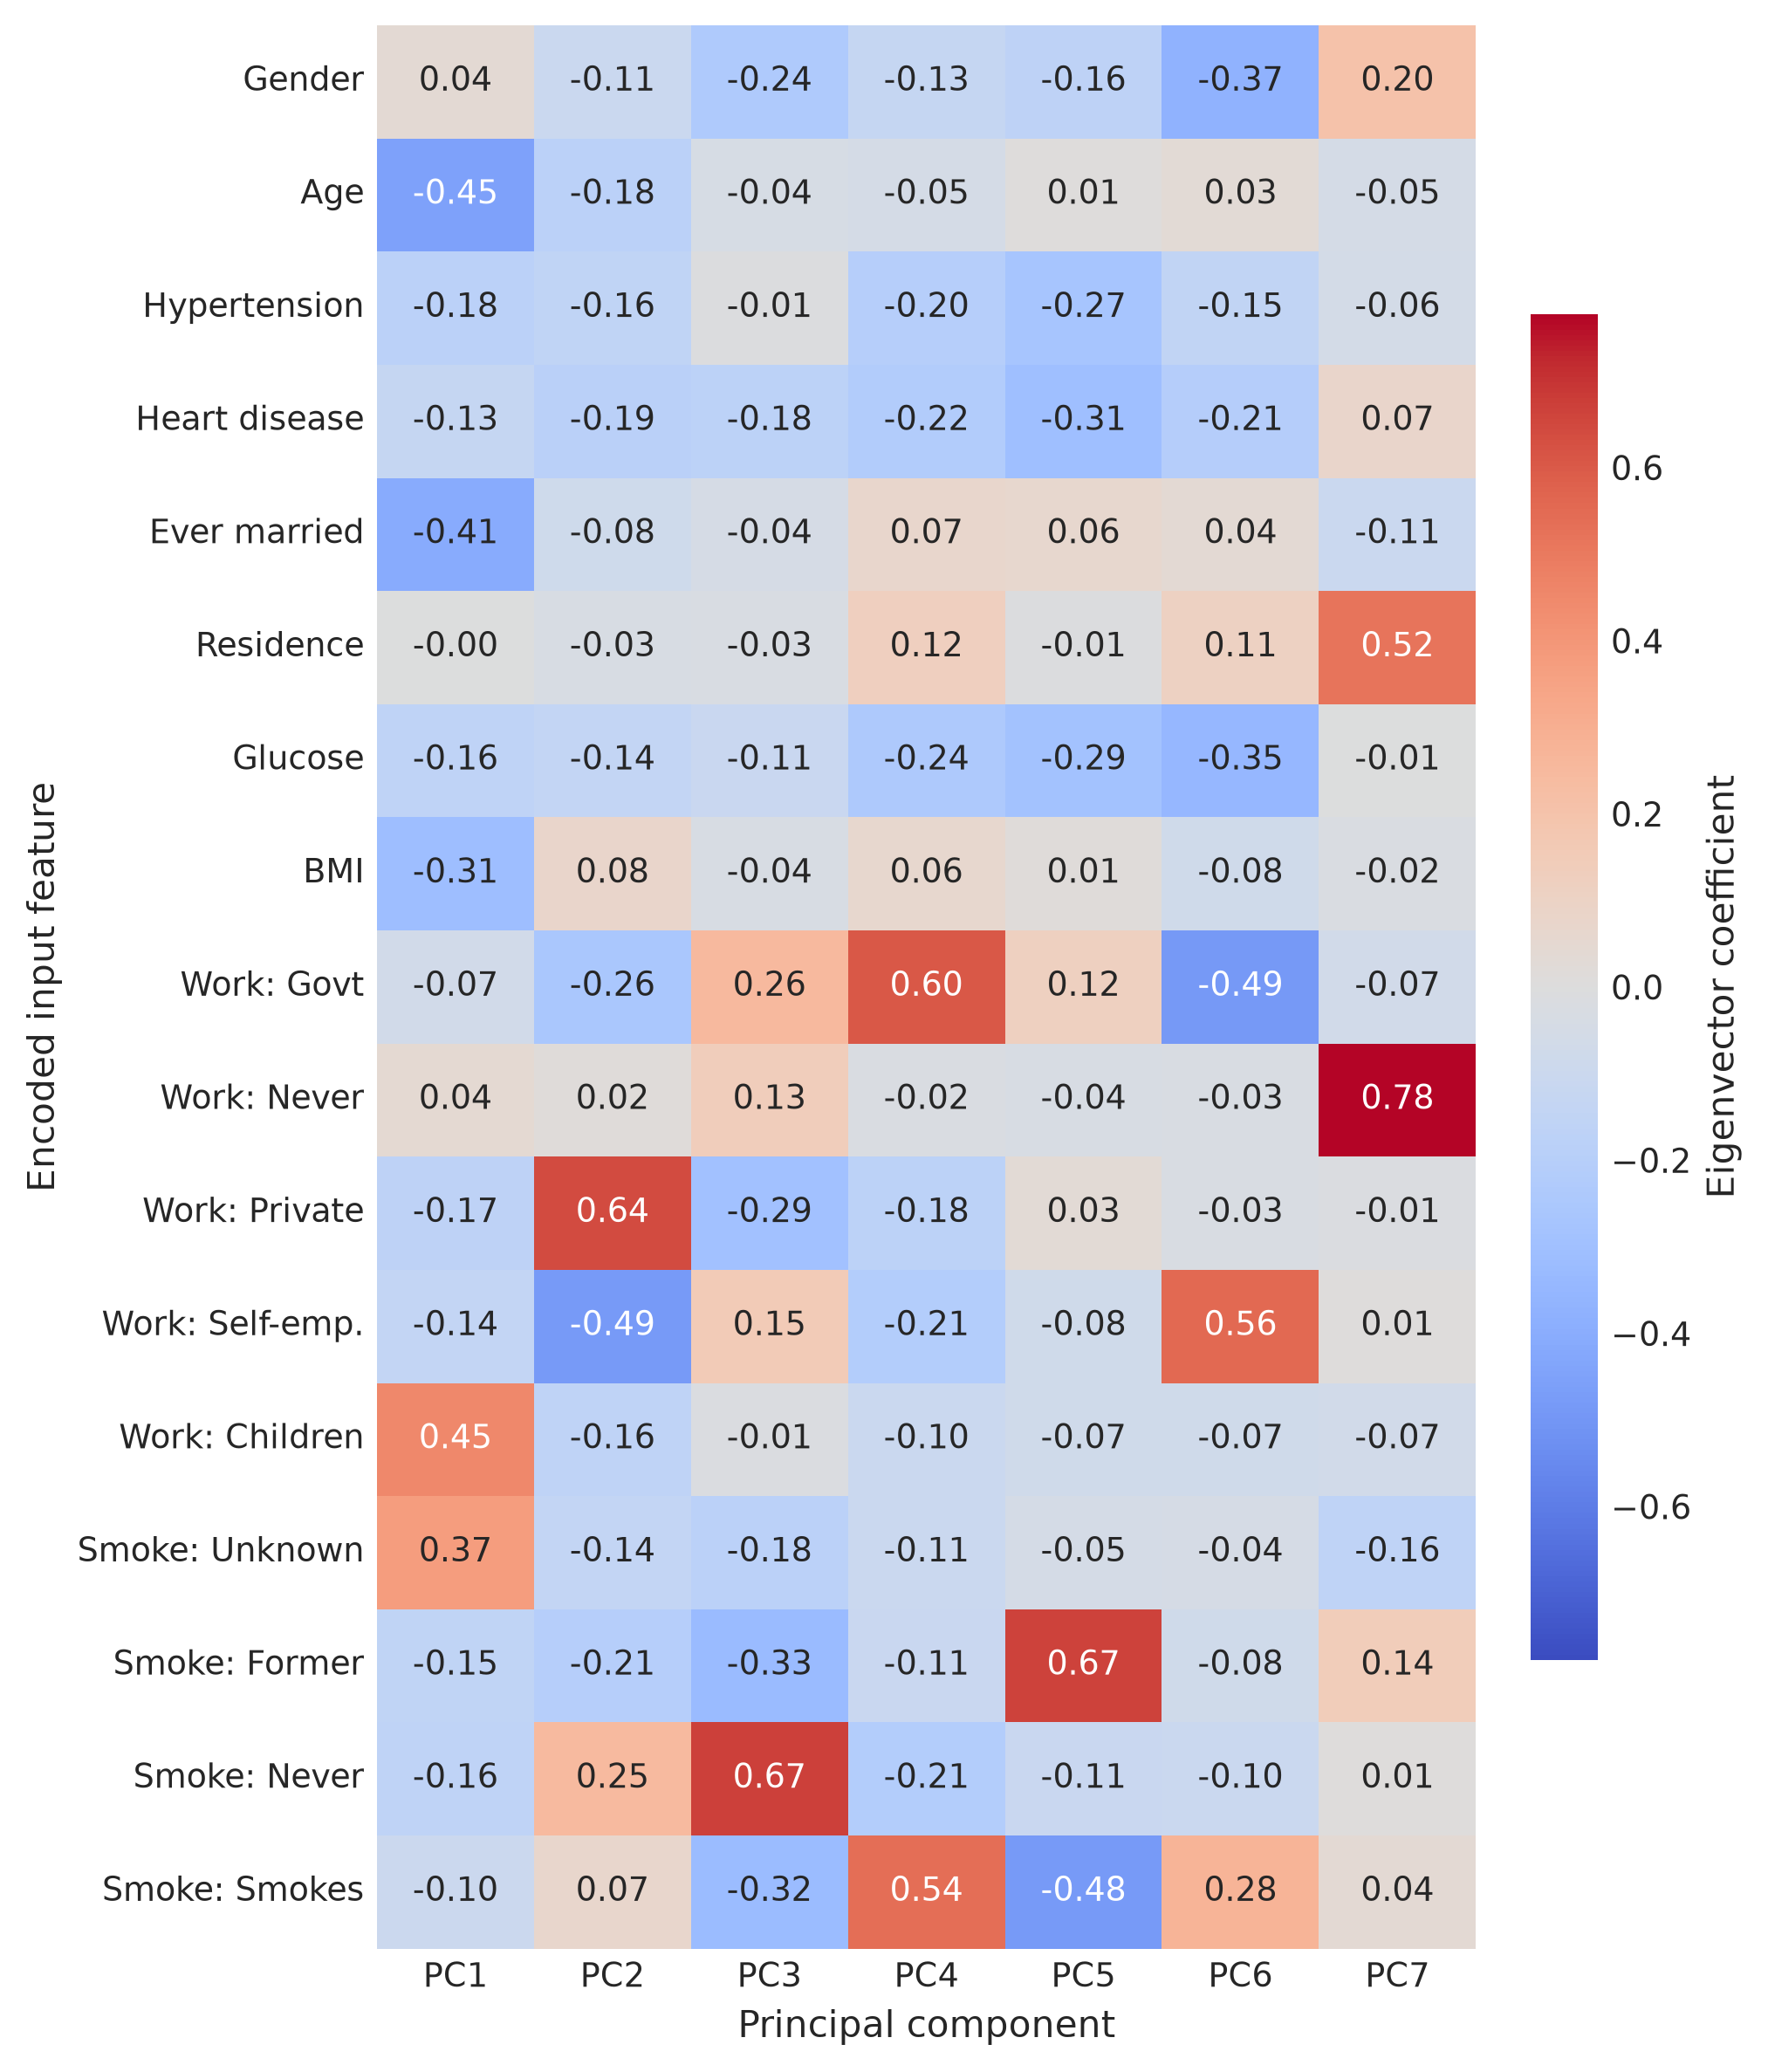

Encoded feature,PC1,PC2
work_type_children,+0.4534,-0.1583
age,-0.4497,-0.1772
ever_married,-0.4076,-0.0803
smoking_status_Unknown,+0.3712,-0.1436
bmi,-0.3133,+0.0771
work_type_Private,-0.1671,+0.6399
work_type_Self-employed,-0.1397,-0.4855
work_type_Govt_job,-0.0703,-0.2558


In [16]:
# Unit-norm eigenvector weights V, not scaled loadings V sqrt(Lambda).
weights_matrix = pd.DataFrame(pca_full.components_[:7].T, index=feature_names,
                              columns=[f'PC{i+1}' for i in range(7)])
fig, ax = plt.subplots(figsize=(6.65, 7.8))
bound = float(np.abs(weights_matrix.to_numpy()).max())
sns.heatmap(weights_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-bound, vmax=bound, ax=ax, annot_kws={'size':9},
            yticklabels=[short_labels[c] for c in weights_matrix.index],
            cbar_kws={'label':'Eigenvector coefficient', 'shrink':0.7})
ax.set(xlabel='Principal component', ylabel='Encoded input feature')
ax.tick_params(axis='y', rotation=0)
finish_figure(fig, 'Figure 8: PCA Eigenvector Weights — PC1 to PC7',
              'Weights refer to standardized encoded inputs. Short labels follow Figure 4b.')
key_features = ['work_type_children', 'age', 'ever_married', 'smoking_status_Unknown',
                'bmi', 'work_type_Private', 'work_type_Self-employed', 'work_type_Govt_job']
key_weights = weights_matrix.loc[key_features, ['PC1','PC2']].copy()
for col in key_weights: key_weights[col] = key_weights[col].map('{:+.4f}'.format)
show_table(key_weights.reset_index().rename(columns={'index':'Encoded feature'}),
           'Table 15. Selected PC1 and PC2 eigenvector weights — standardized data', [56,22,22],
           'Selected coefficients aid interpretation; each full PC includes all encoded inputs.')
for feature in key_features:
    for component in ['PC1','PC2']:
        report_values[f'{component}_{feature}'] = float(weights_matrix.loc[feature, component])


### 2.5. Interpretation and Critical Evaluation

**Coefficient convention.** Figure 8 and Table 15 show unit-norm eigenvector weights $V$, used in $Y=ZV$. A different scaled-loading convention is $L=V\sqrt{\Lambda}$. For this scaling/covariance convention:

For a component with positive variance ($\lambda_j > 0$), the feature–score correlation is:

$$\operatorname{Corr}(Z_k,Y_j)
=\frac{v_{kj}\sqrt{\lambda_j}}{\sqrt{n/(n-1)}}.$$

The correlation is undefined when $\lambda_j = 0$.

These quantities are related but are not interchangeable.

**PC1** contrasts pediatric/unrecorded-smoking profiles (`children`: **+0.4534**; `Unknown`: **+0.3712**) against greater age (**-0.4497**), ever-married status (**-0.4076**), and higher BMI (**-0.3133**). It is a demographic/recording contrast, not a validated clinical risk score.

**PC2** contrasts Private employment (**+0.6399**) against Self-employed (**-0.4855**) and Govt_job (**-0.2558**). Other encoded inputs also contribute, so these selected coefficients are an interpretation rather than the full component equation.

Original encoded variables have non-zero cross-covariances; this does not make their coordinate axes non-orthogonal. PCA projects onto orthogonal directions with diagonal score covariance:

$$\operatorname{Cov}(Y_p)=\frac1{n-1}Y_p^TY_p
=\operatorname{diag}(\lambda_1,\ldots,\lambda_p).$$

Uncorrelated scores do not necessarily imply statistical independence. Original measurements retain their recorded units, whereas PCA scores combine standardized numerical and categorical inputs and no longer have direct clinical units.

<div class="stroke-table-wrap">
<table class="stroke-table">
<caption>Table 16. PCA evaluation &mdash; standardized input representation</caption>
<colgroup><col style="width:28%"><col style="width:36%"><col style="width:36%"></colgroup>
<thead><tr><th>Criterion</th><th>Evidence from this analysis</th><th>Limitation</th></tr></thead>
<tbody>
<tr><td>Information preservation</td><td>10 PCs retain 82.21%; MSE is 0.17793. 15 PCs recover the standardized input to numerical precision.</td><td>Retained variance is not retained target information and does not reverse cleaning.</td></tr>
<tr><td>Interpretability</td><td>Weights reveal demographic, employment, and recording patterns.</td><td>Components mix encoded variables and lack direct clinical units.</td></tr>
<tr><td>Visualization</td><td>Label-colored plots show overlap and centroid shifts.</td><td>PC1&ndash;PC2 retain only 30.15%; a 2D plot does not establish full-space separability.</td></tr>
</tbody></table></div>

For this exploratory task, **$p=10$ (82.21%)** is the primary reduction choice; **$p=12$ (92.08%)** is the higher-retention alternative. Future work could compare prediction with and without PCA under a validation design. Tree ensembles and t-SNE/UMAP are possible future comparisons, not demonstrated improvements or established gold standards in these experiments.


## References

1. **TD1-PCA.** Labwork T1: Principal Component Analysis — assignment specification (`TD1-PCA.pdf`).
2. **DM 2 — Data Preparation and Analysis.** Supplied lecture slides (`DM 2 Data Preparation and Analysis.pdf`), especially pp.5, 8–9, 12–19.
3. **DM 2.5 — Feature Selection.** Supplied lecture slides (`DM 2.5 Feature Selection.pdf`), especially pp.4, 6–12.
4. **DM 3 — Statistics and PCA.** Supplied lecture slides (`DM 3 - Statistics and PCA.pdf`), especially pp.8–20, 24, 27, 29, 33–35.
5. **fedesoriano.** [Stroke Prediction Dataset, Kaggle](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset). Local data file: `healthcare-dataset-stroke-data.csv`.
6. **ML2___Labwork_1.** Supplied reference report (`ML2___Labwork_1.pdf`), consulted for report organization and table/figure layout conventions.

### Final Report Assembly

This notebook covers Dataset 1 only. The final PDF must add Dataset 2 with the same Part 1/Part 2 requirements, fill in student metadata, and use continuous figure/table numbering across the combined report. Place Figure 4b in the appendix; code is optional in the report under TD1-PCA. No Dataset 2 result is inferred here.
